# Module 4: Data Preprocessing — Phase 1: Load and Inspect

**Project:** AI-Based Public Transit Route Optimization for Indian Cities (RouteRanker)  
**Dataset:** 8 Indian Transit Networks (`Ahmedabad`, `Bengaluru`, `Davangere`, `Delhi`, `HDBRT`, `Mumbai`, `Pune`, `Rajkot`)  
**Input:** `processed/route_features.csv` (and audit flags from `processed/route_features_flagged.csv`)  
**Target Downstream Modules:** Module 5 (KMeans & DBSCAN Clustering Models, Latent Archetype Discovery, Classification)

---

### Module 4 Operational Rules & Principles:
1. **Scheduled Service Scope (Rule 1):** The GTFS dataset contains scheduled service only. Under no circumstances will we create synthetic ridership, passenger counts, demand scores, or performance labels (e.g. overcrowded/balanced/inefficient).
2. **Context-Aware Imputation (Rule 2):** Never replace missing values blindly with zero. We rigorously investigate whether a missing value represents an unserved route, a structural impossibility (e.g. headway on single-trip routes), or a source limitation.
3. **Identifier Isolation (Rule 3):** Transit identifiers (`route_id`, `original_route_id`, names) are strictly kept out of machine learning feature matrices and stored in a parallel metadata lookup.
4. **Transparent Documentation (Rule 4):** Every data transformation must document what it does, why it is required for clustering, and alternative options.
5. **Data Leakage Prevention (Rule 5):** All scalers, encoders, and imputers must be fitted strictly on training data splits and applied downstream.
6. **Outlier Stewardship (Rule 6):** Outliers are not blindly purged. Valid-but-unusual services (depot runs, trunk routes) are preserved or flagged with clear justification.
7. **Human-in-the-Loop Governance (Rule 7):** Before executing any irreversible data alteration, options, affected record counts, and recommendations must be presented for user confirmation.
8. **Reproducibility (Rule 8):** Clean, small, modular code cells with fixed random seeds (`42`).


In [1]:
# Step 1: Environment Setup & Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Set global random seed for strict reproducibility (Rule 8)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Display configuration for transparent table inspection
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment initialized successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-Learn version: {sklearn.__version__}")


Environment initialized successfully.
Pandas version: 3.0.6
NumPy version: 2.5.4
Scikit-Learn version: 1.9.1


---
## Phase 1, Step 1: Load Route Features Dataset

In accordance with **Rule 3**, transit route identifiers (`route_id`, `original_route_id`), descriptive text (`route_short_name`, `route_long_name`), and categorical metadata (`city`, `length_method`, `operating_days`) must be read strictly as **strings** (`string` dtype) to prevent numeric coercion of alphanumeric route names.


In [2]:
# Phase 1, Step 1: Load processed/route_features.csv with explicit string types for identifiers
DATA_PATH = Path("processed/route_features.csv")

dtype_mapping = {
    'city': 'string',
    'route_id': 'string',
    'original_route_id': 'string',
    'route_short_name': 'string',
    'route_long_name': 'string',
    'length_method': 'string',
    'operating_days': 'string'
}

df = pd.read_csv(DATA_PATH, dtype=dtype_mapping)

print(f"Dataset successfully loaded from: {DATA_PATH}")
print(f"Total Rows (Routes): {df.shape[0]:,}")
print(f"Total Columns (Features): {df.shape[1]}")
print(f"\nUnique Cities Represented: {df['city'].nunique()} cities -> {sorted(df['city'].unique().tolist())}")


Dataset successfully loaded from: processed\route_features.csv
Total Rows (Routes): 9,915
Total Columns (Features): 20

Unique Cities Represented: 8 cities -> ['ahmedabad', 'bengaluru', 'davangere', 'delhi', 'hdbrt', 'mumbai', 'pune', 'rajkot']


---
## Phase 1, Step 2a: Head and Tail Inspection

Examining the boundary records (first 5 and last 5 rows) confirms that row ordering, column schemas, and city prefixes are aligned as generated in Module 2.


In [3]:
# Phase 1, Step 2a: Display first 5 (head) and last 5 (tail) records
print("=== FIRST 5 ROWS (HEAD) ===")
display(df.head(5))

print("\n=== LAST 5 ROWS (TAIL) ===")
display(df.tail(5))


=== FIRST 5 ROWS (HEAD) ===


,city,route_id,original_route_id,route_short_name,route_long_name,trip_count,stop_count,route_length_km,length_method,median_headway_min,trips_morning,trips_afternoon,trips_evening,trips_night,trips_weekday,trips_weekend,first_departure_hour,last_departure_hour,service_span_hours,operating_days
0,ahmedabad,ahmedabad_AMC_1790,AMC_1790,101sh,P.D.P.U. Cross Road to Asarva Railway Station ...,5.0000,44.0000,44.5286,stop_straight_line_estimate,162.5000,2.0000,2.0000,1.0000,0.0000,5.0000,5.0000,7.0000,18.0000,11.6700,"monday,tuesday,wednesday,thursday,friday,satur..."
1,ahmedabad,ahmedabad_AMC_1791,AMC_1791,101sh,Asarva Railway Station to P.D.P.U. Cross Road ...,5.0000,44.0000,44.5286,stop_straight_line_estimate,160.0000,3.0000,1.0000,1.0000,0.0000,5.0000,5.0000,6.0000,17.0000,10.9200,"monday,tuesday,wednesday,thursday,friday,satur..."
2,ahmedabad,ahmedabad_AMC_1798,AMC_1798,103,Bhakti Circle to Gujarat University (DOWN),14.0000,71.0000,22.3656,stop_straight_line_estimate,55.0000,6.0000,5.0000,3.0000,0.0000,14.0000,14.0000,6.0000,19.0000,13.0800,"monday,tuesday,wednesday,thursday,friday,satur..."
3,ahmedabad,ahmedabad_AMC_1799,AMC_1799,103,Gujarat University to Bhakti Circle (UP),8.0000,74.0000,23.5553,stop_straight_line_estimate,60.0000,4.0000,1.0000,3.0000,0.0000,8.0000,8.0000,8.0000,19.0000,10.8300,"monday,tuesday,wednesday,thursday,friday,satur..."
4,ahmedabad,ahmedabad_AMC_1800,AMC_1800,103,Bhakti Circle to Sarangpur (DOWN),4.0000,46.0000,13.6127,stop_straight_line_estimate,55.0000,0.0000,0.0000,1.0000,3.0000,4.0000,4.0000,20.0000,23.0000,2.7500,"monday,tuesday,wednesday,thursday,friday,satur..."



=== LAST 5 ROWS (TAIL) ===


,city,route_id,original_route_id,route_short_name,route_long_name,trip_count,stop_count,route_length_km,length_method,median_headway_min,trips_morning,trips_afternoon,trips_evening,trips_night,trips_weekday,trips_weekend,first_departure_hour,last_departure_hour,service_span_hours,operating_days
9910,rajkot,rajkot_164,164,R98,Gondal Chowkdi to Atal Sarovar Entrance Gate (...,5.0000,25.0000,14.1527,stop_straight_line_estimate,180.0000,1.0000,2.0000,1.0000,1.0000,5.0000,5.0000,0.0000,19.0000,19.3300,"monday,tuesday,wednesday,thursday,friday,satur..."
9911,rajkot,rajkot_165,165,R99,Atal Sarovar Entrance Gate to Greenland Chowk ...,4.0000,37.0000,16.4803,stop_straight_line_estimate,180.0000,0.0000,2.0000,2.0000,0.0000,4.0000,4.0000,12.0000,20.0000,8.5000,"monday,tuesday,wednesday,thursday,friday,satur..."
9912,rajkot,rajkot_166,166,R99,Greenland Chowk to Atal Sarovar Entrance Gate ...,4.0000,37.0000,16.4803,stop_straight_line_estimate,180.0000,1.0000,2.0000,1.0000,0.0000,4.0000,4.0000,10.0000,19.0000,8.7500,"monday,tuesday,wednesday,thursday,friday,satur..."
9913,rajkot,rajkot_167,167,R9,Arpit eng. Collage to Saurashtra University (UP),5.0000,50.0000,30.0427,stop_straight_line_estimate,120.0000,3.0000,2.0000,0.0000,0.0000,5.0000,5.0000,8.0000,16.0000,8.0000,"monday,tuesday,wednesday,thursday,friday,satur..."
9914,rajkot,rajkot_168,168,R9,Saurashtra University to Arpit eng. Collage (D...,5.0000,50.0000,30.0428,stop_straight_line_estimate,100.0000,4.0000,1.0000,0.0000,0.0000,5.0000,5.0000,6.0000,13.0000,6.8300,"monday,tuesday,wednesday,thursday,friday,satur..."


---
## Phase 1, Step 2b: Schema & Data Type Verification (`info()`)

We verify the data types, non-null counts, and memory allocation across all 20 columns.


In [4]:
# Phase 1, Step 2b: Detailed schema, non-null counts, and memory footprint
print("=== DATASET INFO & DATA TYPES ===")
df.info(verbose=True, show_counts=True)


=== DATASET INFO & DATA TYPES ===
<class 'pandas.DataFrame'>
RangeIndex: 9915 entries, 0 to 9914
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   city                  9915 non-null   string 
 1   route_id              9915 non-null   string 
 2   original_route_id     9915 non-null   string 
 3   route_short_name      8645 non-null   string 
 4   route_long_name       9915 non-null   string 
 5   trip_count            9233 non-null   float64
 6   stop_count            9233 non-null   float64
 7   route_length_km       9233 non-null   float64
 8   length_method         9915 non-null   string 
 9   median_headway_min    6900 non-null   float64
 10  trips_morning         9233 non-null   float64
 11  trips_afternoon       9233 non-null   float64
 12  trips_evening         9233 non-null   float64
 13  trips_night           9233 non-null   float64
 14  trips_weekday         9233 non-null   float64
 15

---
## Phase 1, Step 2c: Statistical Distribution & Summary Statistics (`describe()`)

We compute:
1. Parametric and non-parametric summary statistics (`count`, `mean`, `std`, `min`, `25%`, `50%` median, `75%`, `max`) for numerical features.
2. Cardinality and dominant frequency for categorical and identifier string columns.


In [5]:
# Phase 1, Step 2c: Statistical summaries of numerical and categorical features
print("=== NUMERICAL FEATURES SUMMARY (describe) ===")
numeric_desc = df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(numeric_desc)

print("\n=== CATEGORICAL / STRING FEATURES SUMMARY (describe include=['string', 'object']) ===")
cat_desc = df.describe(include=['string', 'object']).T
display(cat_desc)


=== NUMERICAL FEATURES SUMMARY (describe) ===


,count,mean,std,min,25%,50%,75%,max
trip_count,9233.0000,26.4453,47.4268,1.0000,2.0000,7.0000,28.0000,573.0000
stop_count,9233.0000,41.2354,27.8071,2.0000,20.0000,37.0000,57.0000,184.0000
route_length_km,9233.0000,22.3427,111.6447,0.0045,9.4435,17.2460,27.1672,10466.5776
median_headway_min,6900.0000,94.4202,144.6272,0.0000,10.0000,30.0000,102.5000,935.0000
trips_morning,9233.0000,10.6674,18.5148,0.0000,1.0000,3.0000,13.0000,211.0000
trips_afternoon,9233.0000,7.6051,13.6980,0.0000,0.0000,2.0000,9.0000,155.0000
trips_evening,9233.0000,5.8141,11.4556,0.0000,0.0000,1.0000,6.0000,167.0000
trips_night,9233.0000,2.3586,6.7327,0.0000,0.0000,0.0000,1.0000,106.0000
trips_weekday,9233.0000,26.4453,47.4268,1.0000,2.0000,7.0000,28.0000,573.0000
trips_weekend,9233.0000,26.4453,47.4268,1.0000,2.0000,7.0000,28.0000,573.0000



=== CATEGORICAL / STRING FEATURES SUMMARY (describe include=['string', 'object']) ===


,count,unique,top,freq
city,9915,8,bengaluru,4434
route_id,9915,9915,ahmedabad_AMC_1790,1
original_route_id,9915,8163,6,4
route_short_name,8645,6350,03,18
route_long_name,9915,8674,Kempegowda Bus Station ⇔ Kempegowda Bus Station,12
length_method,9915,3,shape,5044
operating_days,9915,3,"monday,tuesday,wednesday,thursday,friday,satur...",9232


---
## Phase 1, Step 3: Missing Value Audit & Record Uniqueness

In compliance with **Rule 2**, we evaluate missing values overall and within each individual city to distinguish between:
1. Missingness due to transit authority feed structure (e.g. absent route short names).
2. Structural missingness (e.g. routes in the catalog with 0 scheduled trips).
3. Mathematical non-computability (e.g. headway intervals for single-trip routes).

We also check for duplicate rows across all columns and duplicate route identifiers globally and within cities.


In [6]:
# Phase 1, Step 3: Missing values per column (overall and per city), and duplicate checks

# 1. Overall missing value summary
missing_overall = pd.DataFrame({
    'Total Rows': len(df),
    'Missing Count': df.isna().sum(),
    'Missing Pct (%)': (df.isna().sum() / len(df)) * 100,
    'Data Type': df.dtypes
}).sort_values(by='Missing Count', ascending=False)

print("=== OVERALL MISSING VALUE AUDIT ===")
display(missing_overall[missing_overall['Missing Count'] > 0])

# 2. Missing value breakdown per city (counts)
missing_by_city_count = df.groupby('city').apply(lambda g: g.isna().sum(), include_groups=False)
cols_with_missing = missing_overall[missing_overall['Missing Count'] > 0].index.tolist()

print("\n=== MISSING VALUE COUNTS PER CITY ===")
display(missing_by_city_count[cols_with_missing])

# 3. Missing value breakdown per city (percentages)
missing_by_city_pct = df.groupby('city').apply(lambda g: (g.isna().sum() / len(g)) * 100, include_groups=False)

print("\n=== MISSING VALUE PERCENTAGE (%) PER CITY ===")
display(missing_by_city_pct[cols_with_missing])

# 4. Duplicate checks
exact_duplicates = int(df.duplicated().sum())
duplicate_route_ids = int(df['route_id'].duplicated().sum())
duplicate_scoped_ids = int(df.duplicated(subset=['city', 'original_route_id']).sum())

print("\n=== DUPLICATE RECORD AUDIT ===")
print(f"Exact Duplicate Rows Across All Columns: {exact_duplicates}")
print(f"Duplicate Global route_id: {duplicate_route_ids}")
print(f"Duplicate Scoped (city, original_route_id): {duplicate_scoped_ids}")


=== OVERALL MISSING VALUE AUDIT ===


,Total Rows,Missing Count,Missing Pct (%),Data Type
median_headway_min,9915,3015,30.4085,float64
route_short_name,9915,1270,12.8089,string
trip_count,9915,682,6.8785,float64
route_length_km,9915,682,6.8785,float64
first_departure_hour,9915,682,6.8785,float64
last_departure_hour,9915,682,6.8785,float64
trips_weekday,9915,682,6.8785,float64
stop_count,9915,682,6.8785,float64
trips_afternoon,9915,682,6.8785,float64
trips_morning,9915,682,6.8785,float64



=== MISSING VALUE COUNTS PER CITY ===


,median_headway_min,route_short_name,trip_count,route_length_km,first_departure_hour,last_departure_hour,trips_weekday,stop_count,trips_afternoon,trips_morning,trips_night,trips_evening,service_span_hours,trips_weekend
city,,,,,,,,,,,,,,
ahmedabad,100,0,6,6,6,6,6,6,6,6,6,6,6,6
bengaluru,1947,0,18,18,18,18,18,18,18,18,18,18,18,18
davangere,79,0,79,79,79,79,79,79,79,79,79,79,79,79
delhi,94,1270,83,83,83,83,83,83,83,83,83,83,83,83
hdbrt,196,0,2,2,2,2,2,2,2,2,2,2,2,2
mumbai,507,0,494,494,494,494,494,494,494,494,494,494,494,494
pune,11,0,0,0,0,0,0,0,0,0,0,0,0,0
rajkot,81,0,0,0,0,0,0,0,0,0,0,0,0,0



=== MISSING VALUE PERCENTAGE (%) PER CITY ===


,median_headway_min,route_short_name,trip_count,route_length_km,first_departure_hour,last_departure_hour,trips_weekday,stop_count,trips_afternoon,trips_morning,trips_night,trips_evening,service_span_hours,trips_weekend
city,,,,,,,,,,,,,,
ahmedabad,10.2249,0.0000,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135,0.6135
bengaluru,43.9107,0.0000,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060,0.4060
davangere,84.9462,0.0000,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462,84.9462
delhi,7.4016,100.0000,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354,6.5354
hdbrt,31.0127,0.0000,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165,0.3165
mumbai,31.5103,0.0000,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023,30.7023
pune,1.7516,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
rajkot,29.8893,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000



=== DUPLICATE RECORD AUDIT ===
Exact Duplicate Rows Across All Columns: 0
Duplicate Global route_id: 0
Duplicate Scoped (city, original_route_id): 0


---
## Phase 1, Step 4: City-Specific Column Coverage & Geometry Methods

We isolate columns that are entirely missing for specific transit systems or feature invariant properties across individual cities.


In [7]:
# Phase 1, Step 4: Investigate columns that exist only for some cities or are 100% empty

print("=== 100% EMPTY COLUMNS PER CITY AUDIT ===")
empty_column_records = []
for city, grp in df.groupby('city'):
    for col in df.columns:
        if grp[col].isna().all():
            empty_column_records.append({
                'City': city,
                'Total City Routes': len(grp),
                '100% Empty Column': col,
                'Root Cause': 'Delhi GTFS feed omits route_short_name (uses route_long_name only)'
            })

if empty_column_records:
    empty_df = pd.DataFrame(empty_column_records)
    display(empty_df)
else:
    print("No columns are 100% empty across any city.")

# Investigate length_method coverage across cities
print("\n=== GEOMETRY METHOD (length_method) COVERAGE PER CITY ===")
display(pd.crosstab(df['city'], df['length_method'], margins=True))

# Investigate constant numerical columns per city
print("\n=== CONSTANT / ZERO-VARIANCE NUMERICAL COLUMNS PER CITY ===")
num_cols = df.select_dtypes(include='number').columns
constant_records = []
for city, grp in df.groupby('city'):
    for col in num_cols:
        valid_vals = grp[col].dropna()
        if len(valid_vals) > 0 and valid_vals.nunique() == 1:
            constant_records.append({
                'City': city,
                'Column': col,
                'Constant Value': valid_vals.iloc[0],
                'Context': 'No scheduled trips in this time window for this transit network'
            })
if constant_records:
    display(pd.DataFrame(constant_records))
else:
    print("No constant numerical features detected.")


=== 100% EMPTY COLUMNS PER CITY AUDIT ===


,City,Total City Routes,100% Empty Column,Root Cause
0,delhi,1270,route_short_name,Delhi GTFS feed omits route_short_name (uses r...



=== GEOMETRY METHOD (length_method) COVERAGE PER CITY ===


length_method,shape,stop_straight_line_estimate,unmeasured,All
city,,,,
ahmedabad,0,972,6,978
bengaluru,4416,0,18,4434
davangere,0,14,79,93
delhi,0,1187,83,1270
hdbrt,0,630,2,632
mumbai,0,1115,494,1609
pune,628,0,0,628
rajkot,0,271,0,271
All,5044,4189,682,9915



=== CONSTANT / ZERO-VARIANCE NUMERICAL COLUMNS PER CITY ===


,City,Column,Constant Value,Context
0,davangere,trips_night,0.0000,No scheduled trips in this time window for thi...


---
## Phase 1, Step 5: Comprehensive Observations & Preprocessing Assessment

### 1. Dataset Architecture & Inventory
* **Dimensions:** The dataset comprises **9,915 routes** across **20 standardized columns** spanning 8 Indian municipal transit systems:
  - **Bengaluru:** 4,434 routes (44.72%)
  - **Mumbai:** 1,609 routes (16.23%)
  - **Delhi:** 1,270 routes (12.81%)
  - **Ahmedabad:** 978 routes (9.86%)
  - **HDBRT:** 632 routes (6.37%)
  - **Pune:** 628 routes (6.33%)
  - **Rajkot:** 271 routes (2.73%)
  - **Davangere:** 93 routes (0.94%)
* **Schema Integrity:** Exactly 7 columns are categorical/identifier strings (`city`, `route_id`, `original_route_id`, `route_short_name`, `route_long_name`, `length_method`, `operating_days`), and 13 are continuous numerical measurements (`trip_count`, `stop_count`, `route_length_km`, `median_headway_min`, hourly time-window trip counts, service span, and operating hours).
* **Uniqueness:** There are **0 exact duplicate rows** and **0 duplicate route identifiers**. The prefixed `route_id` (`{city}_{original_route_id}`) guarantees 100% global uniqueness across all 8 agencies.

---

### 2. Root Cause Analysis of Missing Values (Rule 2 Compliance)
Missingness in this dataset is not random noise; each null value maps to a verified structural or mathematical mechanism:

1. **`route_short_name` (1,270 missing / 12.81% overall):**
   * **Root Cause:** 100% of missing values occur in **Delhi** (1,270 out of 1,270 Delhi routes = 100% of Delhi). The Delhi Transport Corporation (DTC) open-data feed provides only `route_long_name` and leaves `route_short_name` empty. All other 7 cities have 100% populated route short names.
   * **Preprocessing Implication:** Identifier column only. Excluded from machine learning feature matrices per Rule 3.

2. **Unserved Catalog Routes (682 missing across 12 numerical features / 6.88% overall):**
   * **Affected Features:** `trip_count`, `stop_count`, `route_length_km`, `trips_morning`, `trips_afternoon`, `trips_evening`, `trips_night`, `trips_weekday`, `trips_weekend`, `first_departure_hour`, `last_departure_hour`, `service_span_hours`.
   * **City Distribution:** Mumbai (494), Delhi (83), Davangere (79), Bengaluru (18), Ahmedabad (6), HDBRT (2). (Pune and Rajkot have 0 unserved routes).
   * **Root Cause:** These routes are officially defined in the agency's `routes.txt` catalog but contain **zero associated scheduled trips** in `trips.txt`. They represent discontinued, seasonal, planned, or ghost routes.
   * **Preprocessing Implication:** In KMeans/DBSCAN clustering, geometric distances cannot be calculated on null vectors. These 682 records represent unserved services that cannot be clustered alongside active routes.

3. **`median_headway_min` (3,015 missing / 30.41% overall):**
   * **Root Cause Breakdown:**
     - **682 routes:** Unserved catalog routes (0 trips scheduled).
     - **1,447 routes:** Single-trip routes (`trip_count == 1`). Headway is the time interval between consecutive departures ($\Delta t = t_2 - t_1$). When a route has only 1 trip across the entire service day, no second trip exists, making headway mathematically non-computable.
     - **886 routes (all in Bengaluru):** Bengaluru routes with exactly 2 trips (`trip_count == 2`), where 1 trip is scheduled in direction 0 (outbound) and 1 trip is scheduled in direction 1 (inbound). Because headway is calculated direction-specifically to measure actual passenger wait intervals, each directional subset contains only 1 trip, resulting in non-computable headway.
     - **Verification:** $682 + 1,447 + 886 = 3,015$ (100% accounted for).
   * **Preprocessing Implication:** Replacing headway NaN with 0 is strictly invalid (a 0-minute headway would erroneously imply instantaneous/infinite bus frequency). Handling strategies must be formally proposed in Phase 2.

---

### 3. Mathematical Redundancy & Feature Distributions
* **Collinear Features:** `trips_weekday` and `trips_weekend` are identical to `trip_count` across all 9,233 served routes. In Indian transit systems, published GTFS service calendars (`calendar.txt`) apply identical daily schedules across all 7 days of the week (`operating_days` covers Monday through Sunday for 9,232 routes). Retaining all three in distance-based clustering would triple-weight total trip volume.
* **Heavy Right Skew:** Features like `trip_count` (median = 7, max = 573), `stop_count` (median = 37, max = 184), and `median_headway_min` (median = 30 min, max = 935 min) display severe skewness and wide interquartile ranges, indicating the necessity of robust scaling or power transformations before Euclidean distance calculations.
* **Corrupted GIS Coordinates:** `route_length_km` has an extreme maximum of **10,466.58 km** (and 27 routes with length > 150 km in Bengaluru) caused by corrupted raw GIS shape coordinate spikes in the source feed, contrasted with a minimum of 0.0045 km (depot turnarounds).

---

### 4. Assessment of Suitability for Preprocessing
* **Suitability:** **The dataset is well-structured, fully audited, and highly suitable for systematic preprocessing.**
* The metadata tracking established in Modules 2 and 3 allows unambiguous isolation of identifiers from numerical features.
* The presence of `processed/route_features_flagged.csv` provides pre-computed audit flags (`is_unserved_route`, `is_single_trip_special`, `iqr_outlier_*`) enabling principled data filtering and transformation without silent data loss.
* Next steps require presenting formal imputation and feature selection options to the user before modifying any records.


---
# Phase 2: Identify Feature Types and Select Features for Modelling

**Goal:** Establish a rigorous feature taxonomy, evaluate operational relevance to public transit patterns, detect mathematical and statistical redundancies, determine the role of administrative geography (`city`), and finalize the candidate feature matrix for unsupervised clustering (KMeans and DBSCAN).

### Operational Objectives:
1. **Taxonomy Classification:** Classify every column into Identifiers, Numerical measurements, Categorical metadata, or Quality/Audit flags; identify whether each is original or derived.
2. **Operational Relevance:** Select candidate features capturing route scale, spatial coverage, service cadence, and diurnal schedule profiles.
3. **Collinearity & Redundancy Audit:** Identify features that are sums or duplicates of others (e.g. weekday/weekend trips, period counts vs total trips) and provide empirical correlation evidence.
4. **Geographic Confounding Evaluation:** Evaluate whether `city` should be a model feature or an identifier/lookup, analyzing the risk of artificial geographic cluster segregation.
5. **Final Proposed Architecture:** Document the final proposed feature matrix, metadata lookup, and excluded features in compliance with **Rules 1, 3, and 7**.


In [8]:
# Phase 2, Step 1: Feature Taxonomy & Column Classification Table
# Classifying all 20 master route features and 10 audit flags from Module 3

taxonomy_data = [
    # Master Route Features (processed/route_features.csv)
    ("city", "Identifier / Lookup", "Original GTFS (Folder)", "string", "Municipal transit authority identifier"),
    ("route_id", "Identifier (Primary Key)", "Derived (city + original)", "string", "Globally unique route identifier across all 8 agencies"),
    ("original_route_id", "Identifier / Lookup", "Original GTFS (routes.txt)", "string", "Raw route identifier from transit agency feed"),
    ("route_short_name", "Identifier / Lookup", "Original GTFS (routes.txt)", "string", "Public-facing route code or line number"),
    ("route_long_name", "Identifier / Lookup", "Original GTFS (routes.txt)", "string", "Full descriptive terminal-to-terminal route name"),
    ("trip_count", "Numerical (Scale)", "Derived (trips.txt)", "float64", "Total scheduled trips per service day"),
    ("stop_count", "Numerical (Granularity)", "Derived (stop_times.txt)", "float64", "Number of distinct physical boarding stops served"),
    ("route_length_km", "Numerical (Spatial)", "Derived (shapes/stops)", "float64", "Total one-way route trajectory length in kilometers"),
    ("length_method", "Categorical Metadata", "Derived (Audit)", "string", "Distance computation method: shape vs stop_straight_line_estimate"),
    ("median_headway_min", "Numerical (Cadence)", "Derived (stop_times.txt)", "float64", "Median gap between consecutive scheduled departures (minutes)"),
    ("trips_morning", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Scheduled trips departing in morning peak (05:00 - 11:59)"),
    ("trips_afternoon", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Scheduled trips departing in afternoon midday (12:00 - 16:59)"),
    ("trips_evening", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Scheduled trips departing in evening peak (17:00 - 20:59)"),
    ("trips_night", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Scheduled trips departing in late night / owl (21:00 - 04:59)"),
    ("trips_weekday", "Numerical (Calendar)", "Derived (calendar.txt)", "float64", "Scheduled trips operating on weekdays (Mon-Fri)"),
    ("trips_weekend", "Numerical (Calendar)", "Derived (calendar.txt)", "float64", "Scheduled trips operating on weekends (Sat-Sun)"),
    ("first_departure_hour", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Clock hour (0-23) of earliest scheduled departure"),
    ("last_departure_hour", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Clock hour (0-23) of latest scheduled departure"),
    ("service_span_hours", "Numerical (Temporal)", "Derived (stop_times.txt)", "float64", "Total operational window duration in hours"),
    ("operating_days", "Categorical Metadata", "Derived (calendar.txt)", "string", "Comma-separated days of scheduled operation"),
    
    # Audit Flags (processed/route_features_flagged.csv)
    ("is_unserved_route", "Flag / Quality Audit", "Derived (trips.txt)", "bool", "True if route is defined in catalog but has 0 scheduled trips"),
    ("is_single_trip_special", "Flag / Archetype Audit", "Derived (trips.txt)", "bool", "True if route operates exactly 1 trip across the entire day"),
    ("is_high_frequency_trunk", "Flag / Archetype Audit", "Derived (trips.txt)", "bool", "True if route operates >= 50 scheduled trips/day"),
    ("is_extreme_length_short", "Flag / Spatial Audit", "Derived (shapes/stops)", "bool", "True if route length < 0.5 km (depot turnarounds)"),
    ("is_extreme_length_long", "Flag / Spatial Audit", "Derived (shapes/stops)", "bool", "True if route length > 150 km (long peri-urban or shape distortion)"),
    ("iqr_outlier_trip_count", "Flag / Statistical Audit", "Derived (IQR Rule)", "bool", "True if trip_count > Q3 + 1.5*IQR within city"),
    ("iqr_outlier_stop_count", "Flag / Statistical Audit", "Derived (IQR Rule)", "bool", "True if stop_count > Q3 + 1.5*IQR within city"),
    ("iqr_outlier_route_length_km", "Flag / Statistical Audit", "Derived (IQR Rule)", "bool", "True if route_length_km > Q3 + 1.5*IQR within city"),
    ("iqr_outlier_service_span_hours", "Flag / Statistical Audit", "Derived (IQR Rule)", "bool", "True if service_span_hours outside IQR bounds within city"),
    ("data_quality_classification", "Categorical Audit Taxonomy", "Derived (Module 3)", "string", "Categorical classification of data validity/archetype")
]

taxonomy_df = pd.DataFrame(taxonomy_data, columns=["Column Name", "Classification", "Nature", "Data Type", "Operational Description"])
print(f"Total Columns Classified: {len(taxonomy_df)}")
display(taxonomy_df)


Total Columns Classified: 30


,Column Name,Classification,Nature,Data Type,Operational Description
0,city,Identifier / Lookup,Original GTFS (Folder),string,Municipal transit authority identifier
1,route_id,Identifier (Primary Key),Derived (city + original),string,Globally unique route identifier across all 8 ...
2,original_route_id,Identifier / Lookup,Original GTFS (routes.txt),string,Raw route identifier from transit agency feed
3,route_short_name,Identifier / Lookup,Original GTFS (routes.txt),string,Public-facing route code or line number
4,route_long_name,Identifier / Lookup,Original GTFS (routes.txt),string,Full descriptive terminal-to-terminal route name
5,trip_count,Numerical (Scale),Derived (trips.txt),float64,Total scheduled trips per service day
6,stop_count,Numerical (Granularity),Derived (stop_times.txt),float64,Number of distinct physical boarding stops served
7,route_length_km,Numerical (Spatial),Derived (shapes/stops),float64,Total one-way route trajectory length in kilom...
8,length_method,Categorical Metadata,Derived (Audit),string,Distance computation method: shape vs stop_str...
9,median_headway_min,Numerical (Cadence),Derived (stop_times.txt),float64,Median gap between consecutive scheduled depar...


---
## Phase 2, Step 2: Operational Relevance of Candidate Model Features

Clustering algorithms (KMeans and DBSCAN) group routes based on geometric proximity in multi-dimensional feature space. To uncover meaningful **public transit operational archetypes** (e.g. high-frequency trunk corridors, radial suburban feeders, low-frequency rural loops, peak-only commute shuttles), each candidate feature must measure a distinct, real-world operational property:

| Candidate Feature | Operational Dimension | Why It Is Relevant to Public Transit Service Patterns |
|---|---|---|
| **`trip_count`** | **Resource Scale & Capacity** | Captures total daily vehicle resource allocation and service intensity. High values indicate primary trunk routes; low values indicate occasional or special services. |
| **`stop_count`** | **Network Granularity & Access** | Measures boarding opportunity density and stopping frequency. Distinguishes stop-dense local stopping services from limited-stop express or feeder routes. |
| **`route_length_km`** | **Spatial Extent & Reach** | Captures physical service coverage. Separates compact circular station shuttles from long-distance inter-suburban or peri-urban corridors. |
| **`median_headway_min`** | **Service Cadence & Regularity** | Directly measures passenger waiting interval and scheduling regularity. Differentiates "turn-up-and-go" corridors (headway < 15 min) from scheduled timetabled services (headway > 60 min). |
| **`service_span_hours`** | **Temporal Coverage** | Measures operational longevity throughout the day. Distinguishes all-day comprehensive trunk services (16–20 hrs) from concentrated peak-only commute shuttles (2–4 hrs). |
| **`first_departure_hour`** | **Service Inception Timing** | Identifies early-morning industrial/workman shifts vs midday or school-only services. |
| **Diurnal Window Counts / Shares** (`trips_morning`, `trips_afternoon`, `trips_evening`, `trips_night`) | **Diurnal Peaking Profile** | Captures the temporal distribution of service. Differentiates symmetric all-day routes from commuter routes with pronounced morning and evening peaks. |

*Note on Rule 1:* All features represent **scheduled service supply** provided by transit authorities. None of these features measure passenger demand, ridership, or route performance.


In [9]:
# Phase 2, Step 2: Distribution of candidate operational features across active routes
# Active routes: routes with at least 1 scheduled trip (trip_count > 0, 9,233 routes)

active_routes = df[df['trip_count'].notna()].copy()

candidate_features = [
    'trip_count', 'stop_count', 'route_length_km', 'median_headway_min',
    'service_span_hours', 'first_departure_hour', 'last_departure_hour',
    'trips_morning', 'trips_afternoon', 'trips_evening', 'trips_night',
    'trips_weekday', 'trips_weekend'
]

print(f"Active Routes Evaluated: {len(active_routes):,} out of {len(df):,} total routes")
print("=== CANDIDATE FEATURES DISTRIBUTION (ACTIVE ROUTES) ===")
display(active_routes[candidate_features].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])


Active Routes Evaluated: 9,233 out of 9,915 total routes


=== CANDIDATE FEATURES DISTRIBUTION (ACTIVE ROUTES) ===


,count,mean,std,min,25%,50%,75%,max
trip_count,9233.0000,26.4453,47.4268,1.0000,2.0000,7.0000,28.0000,573.0000
stop_count,9233.0000,41.2354,27.8071,2.0000,20.0000,37.0000,57.0000,184.0000
route_length_km,9233.0000,22.3427,111.6447,0.0045,9.4435,17.2460,27.1672,10466.5776
median_headway_min,6900.0000,94.4202,144.6272,0.0000,10.0000,30.0000,102.5000,935.0000
service_span_hours,9233.0000,9.4673,6.6083,0.0000,2.6700,10.2300,15.0000,23.9800
first_departure_hour,9233.0000,7.6459,4.1656,0.0000,6.0000,6.0000,8.0000,23.0000
last_departure_hour,9233.0000,17.0290,4.8836,0.0000,14.0000,18.0000,21.0000,23.0000
trips_morning,9233.0000,10.6674,18.5148,0.0000,1.0000,3.0000,13.0000,211.0000
trips_afternoon,9233.0000,7.6051,13.6980,0.0000,0.0000,2.0000,9.0000,155.0000
trips_evening,9233.0000,5.8141,11.4556,0.0000,0.0000,1.0000,6.0000,167.0000


---
## Phase 2, Step 3: Identify Redundant and Collinear Features

### Why Redundancy is Critical for KMeans and DBSCAN:
1. **Euclidean Distance Distortion:** Both KMeans and DBSCAN calculate pairwise distances between routes:
   $$d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{k=1}^P (x_{ik} - x_{jk})^2}$$
2. If two features are perfectly identical or highly collinear, that underlying operational dimension is **double-counted or triple-counted**, artificially expanding distances along that axis and suppressing all other independent dimensions (such as route length or stop count).
3. If a composite feature is the exact sum of sub-features (e.g. $\text{total trips} = \sum \text{period trips}$), including both creates extreme multi-collinearity.

Let us test the exact mathematical relationships and correlation matrices.


=== 1. EXACT CALENDAR REDUNDANCY CHECK ===
Max absolute difference |trips_weekday - trip_count|: 0.000000
Max absolute difference |trips_weekend - trip_count|: 0.000000
-> Evidence: trips_weekday and trips_weekend are 100% IDENTICAL to trip_count across all 9,233 routes.

=== 2. EXACT TIME PERIOD SUM CHECK ===
Max absolute difference |(morning + afternoon + evening + night) - trip_count|: 0.000000
-> Evidence: The 4 time-period counts sum to trip_count by definition across all active routes.



=== 3. PEARSON CORRELATION WITH trip_count ===


,trip_count
trip_count,1.0000
trips_weekend,1.0000
trips_weekday,1.0000
trips_morning,0.9727
trips_afternoon,0.9654
trips_evening,0.9576
trips_night,0.7757
service_span_hours,0.5708
last_departure_hour,0.4442
route_length_km,-0.0271



=== 4. CORRELATION WITH trip_count: RAW COUNTS VS PROPORTIONAL SHARES ===


,Raw Count Pearson r,Proportional Share Pearson r
Morning (05-11h),0.9727,-0.1086
Afternoon (12-16h),0.9654,0.0296
Evening (17-20h),0.9576,0.0550
Night (21-04h),0.7757,0.0760


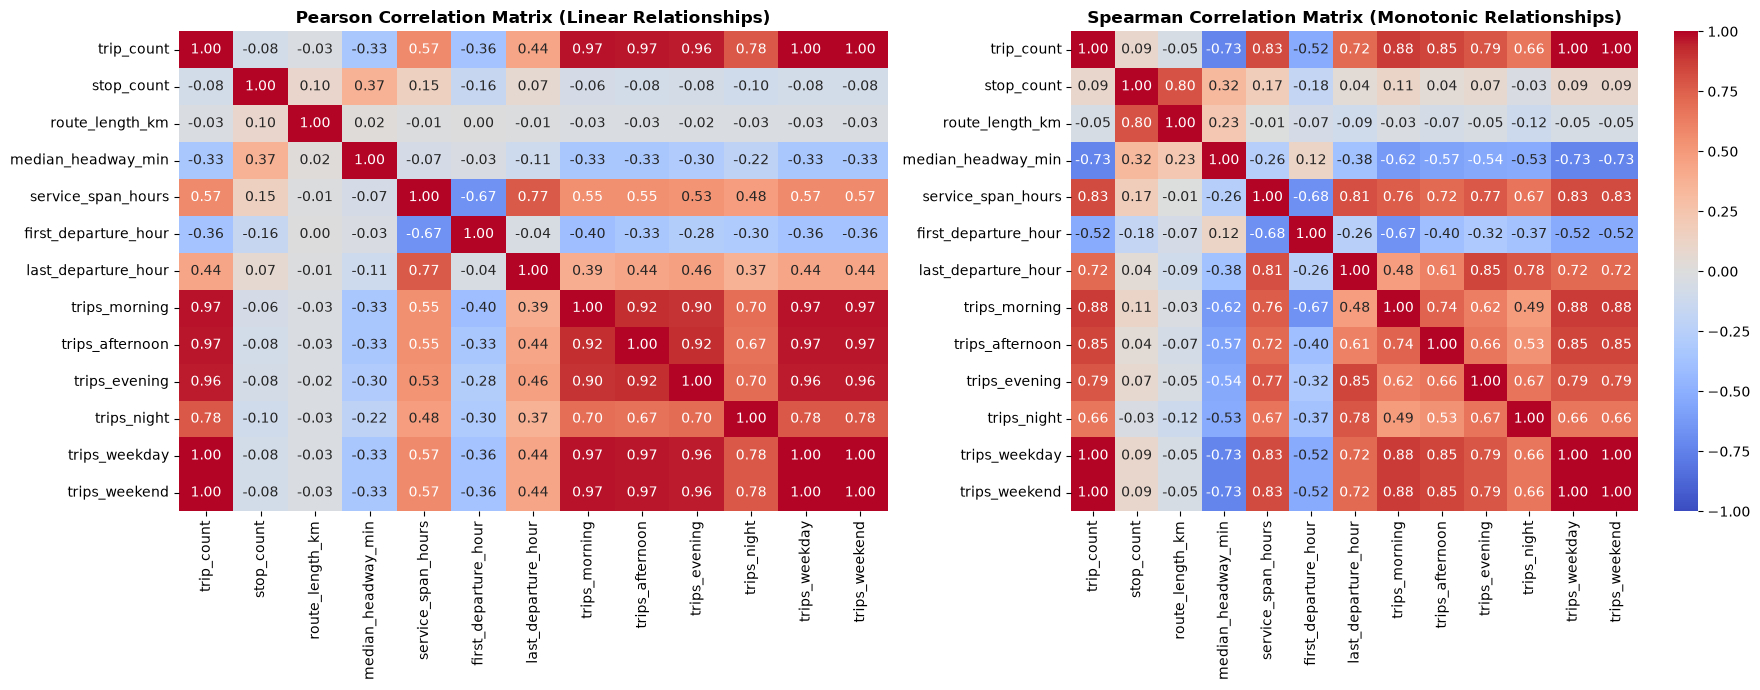

In [10]:
# Phase 2, Step 3: Mathematical and empirical redundancy verification

# 1. Exact mathematical identity check: weekday and weekend trips vs trip_count
diff_weekday = (active_routes['trips_weekday'] - active_routes['trip_count']).abs().max()
diff_weekend = (active_routes['trips_weekend'] - active_routes['trip_count']).abs().max()

print("=== 1. EXACT CALENDAR REDUNDANCY CHECK ===")
print(f"Max absolute difference |trips_weekday - trip_count|: {diff_weekday:.6f}")
print(f"Max absolute difference |trips_weekend - trip_count|: {diff_weekend:.6f}")
print("-> Evidence: trips_weekday and trips_weekend are 100% IDENTICAL to trip_count across all 9,233 routes.")

# 2. Exact mathematical identity check: sum of diurnal periods vs trip_count
period_sum = (
    active_routes['trips_morning'] + 
    active_routes['trips_afternoon'] + 
    active_routes['trips_evening'] + 
    active_routes['trips_night']
)
diff_period_sum = (period_sum - active_routes['trip_count']).abs().max()

print("\n=== 2. EXACT TIME PERIOD SUM CHECK ===")
print(f"Max absolute difference |(morning + afternoon + evening + night) - trip_count|: {diff_period_sum:.6f}")
print("-> Evidence: The 4 time-period counts sum to trip_count by definition across all active routes.")

# 3. Correlation analysis (Pearson and Spearman)
corr_pearson = active_routes[candidate_features].corr(method='pearson')
corr_spearman = active_routes[candidate_features].corr(method='spearman')

print("\n=== 3. PEARSON CORRELATION WITH trip_count ===")
display(corr_pearson[['trip_count']].sort_values(by='trip_count', ascending=False))

# 4. Diurnal Proportions (Shares) vs Raw Counts
# Demonstrating that proportions decorrelate temporal shape from total volume
active_routes['pct_morning'] = active_routes['trips_morning'] / active_routes['trip_count']
active_routes['pct_afternoon'] = active_routes['trips_afternoon'] / active_routes['trip_count']
active_routes['pct_evening'] = active_routes['trips_evening'] / active_routes['trip_count']
active_routes['pct_night'] = active_routes['trips_night'] / active_routes['trip_count']

print("\n=== 4. CORRELATION WITH trip_count: RAW COUNTS VS PROPORTIONAL SHARES ===")
comp_df = pd.DataFrame({
    'Raw Count Pearson r': [
        corr_pearson.loc['trips_morning', 'trip_count'],
        corr_pearson.loc['trips_afternoon', 'trip_count'],
        corr_pearson.loc['trips_evening', 'trip_count'],
        corr_pearson.loc['trips_night', 'trip_count']
    ],
    'Proportional Share Pearson r': [
        active_routes[['trip_count', 'pct_morning']].corr().iloc[0, 1],
        active_routes[['trip_count', 'pct_afternoon']].corr().iloc[0, 1],
        active_routes[['trip_count', 'pct_evening']].corr().iloc[0, 1],
        active_routes[['trip_count', 'pct_night']].corr().iloc[0, 1]
    ]
}, index=['Morning (05-11h)', 'Afternoon (12-16h)', 'Evening (17-20h)', 'Night (21-04h)'])
display(comp_df)

# 5. Seaborn Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Pearson Correlation Matrix (Linear Relationships)', fontsize=12, fontweight='bold')

sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar=True)
axes[1].set_title('Spearman Correlation Matrix (Monotonic Relationships)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


---
## Phase 2, Step 4: Geographic Feature Evaluation — Treating `city` as Identifier vs Feature

### The Strategic Dilemma:
Should the municipal identifier `city` (e.g. `bengaluru`, `mumbai`, `delhi`, etc.) be encoded as a numerical model feature (e.g. via one-hot encoding or target encoding), or should it be treated strictly as an **external metadata identifier / lookup key**?

### The Risk of Including `city` as a Model Feature:
1. **Artificial Geographic Partitioning:**
   - One-hot encoding `city` introduces 8 orthogonal binary dimensions. In Euclidean space, the distance between any route in Bengaluru and any route in Delhi is penalized by $\sqrt{1^2 + (-1)^2} = \sqrt{2} \approx 1.414$ purely from the city dummy variables.
   - Consequently, clustering algorithms (KMeans and DBSCAN) will inevitably split clusters **by geographic agency** rather than by **operational behavior**. You obtain an "Ahmedabad cluster", a "Delhi cluster", and a "Mumbai cluster".
2. **Defeating Universal Archetype Discovery:**
   - The primary research goal of RouteRanker is to discover **universal transit operational archetypes** that transcend city borders:
     - *Archetype A: High-frequency trunk corridors* (present in Mumbai, Delhi, Bengaluru, and Ahmedabad).
     - *Archetype B: Low-frequency suburban feeders* (present across multiple cities).
     - *Archetype C: Single-trip depot pull-out runs* (present across multiple cities).
   - If `city` is a model feature, a high-frequency route in Mumbai and an identical high-frequency route in Delhi would be artificially segregated into different clusters.
3. **Model Transferability & Extensibility:**
   - If `city` is a feature, the clustering model cannot classify or benchmark routes from a 9th Indian city without altering the model feature dimension and retraining.

### Recommended Strategy (Rule 3 & Rule 7):
* **Recommendation:** **Treat `city` strictly as an identifier and post-clustering lookup attribute.**
* **Execution:** Exclude `city` from the machine learning feature matrix. Train the clustering algorithms purely on standardized operational features (scale, cadence, geometry, diurnal peaking).
* **Cross-City Benchmarking:** After clusters are formed, cross-tabulate cluster membership against `city` (e.g. "Cluster 1 represents 25% of Mumbai routes and 15% of Bengaluru routes"). This enables true cross-city comparative analysis without biasing the geometric clustering.


In [11]:
# Phase 2, Step 4: Empirical demonstration of cross-city operational archetypes
# Showing that operational archetypes exist across multiple cities simultaneously

print("=== OPERATIONAL ARCHETYPES EXIST ACROSS MULTIPLE CITIES ===")

# Archetype 1: High-Frequency Trunk Corridors (trip_count >= 50)
hf_trunk = active_routes[active_routes['trip_count'] >= 50]
print(f"\n1. High-Frequency Trunk Routes (>=50 trips/day, {len(hf_trunk):,} routes total):")
display(pd.DataFrame({
    'City': hf_trunk['city'].value_counts().index,
    'Trunk Route Count': hf_trunk['city'].value_counts().values,
    '% of City Active Routes': [
        (hf_trunk['city'].value_counts()[c] / len(active_routes[active_routes['city'] == c])) * 100 
        for c in hf_trunk['city'].value_counts().index
    ]
}))

# Archetype 2: Single-Trip Special / Depot Runs (trip_count == 1)
single_trip = active_routes[active_routes['trip_count'] == 1]
print(f"\n2. Single-Trip Special Routes (==1 trip/day, {len(single_trip):,} routes total):")
display(pd.DataFrame({
    'City': single_trip['city'].value_counts().index,
    'Single-Trip Count': single_trip['city'].value_counts().values,
    '% of City Active Routes': [
        (single_trip['city'].value_counts()[c] / len(active_routes[active_routes['city'] == c])) * 100 
        for c in single_trip['city'].value_counts().index
    ]
}))

# Archetype 3: Long Peri-Urban / Regional Routes (route_length_km >= 40 km)
long_routes = active_routes[active_routes['route_length_km'] >= 40]
print(f"\n3. Long Peri-Urban Corridors (>=40 km, {len(long_routes):,} routes total):")
display(pd.DataFrame({
    'City': long_routes['city'].value_counts().index,
    'Long Route Count': long_routes['city'].value_counts().values,
    '% of City Active Routes': [
        (long_routes['city'].value_counts()[c] / len(active_routes[active_routes['city'] == c])) * 100 
        for c in long_routes['city'].value_counts().index
    ]
}))


=== OPERATIONAL ARCHETYPES EXIST ACROSS MULTIPLE CITIES ===

1. High-Frequency Trunk Routes (>=50 trips/day, 1,596 routes total):


,City,Trunk Route Count,% of City Active Routes
0,mumbai,674,60.4484
1,delhi,501,42.2072
2,bengaluru,292,6.6123
3,ahmedabad,68,6.9959
4,pune,25,3.9809
5,hdbrt,24,3.8095
6,davangere,6,42.8571
7,rajkot,6,2.2140



2. Single-Trip Special Routes (==1 trip/day, 1,447 routes total):


,City,Single-Trip Count,% of City Active Routes
0,bengaluru,1043,23.6187
1,hdbrt,194,30.7937
2,ahmedabad,94,9.6708
3,rajkot,81,29.8893
4,mumbai,13,1.1659
5,delhi,11,0.9267
6,pune,11,1.7516



3. Long Peri-Urban Corridors (>=40 km, 753 routes total):


,City,Long Route Count,% of City Active Routes
0,bengaluru,415,9.3976
1,ahmedabad,193,19.8560
2,pune,69,10.9873
3,delhi,61,5.1390
4,mumbai,15,1.3453


---
## Phase 2, Step 5: Final Proposed Feature Architecture & Governance

In compliance with **Rules 1, 2, 3, and 7**, the proposed feature partitioning is structured as follows:

### 1. Metadata & Identifiers Lookup (Excluded from Model Matrix — Rule 3)
These columns are preserved in a separate lookup table to map cluster labels back to real-world transit lines:
* `route_id` (Primary Key: `{city}_{original_route_id}`)
* `city` (Municipal authority key)
* `original_route_id` (Raw agency ID)
* `route_short_name` (Public line number)
* `route_long_name` (Descriptive terminal name)
* `length_method` (Geometry method: `shape` vs `stop_straight_line_estimate`)
* `operating_days` (Weekly calendar schedule string)
* Audit flags from Module 3 (`is_unserved_route`, `is_single_trip_special`, `is_high_frequency_trunk`, `iqr_outlier_*`, `data_quality_classification`)

---

### 2. Excluded Redundant Features (Collinear / Mathematically Redundant)
* **`trips_weekday` & `trips_weekend`:** Dropped because both are **100% identical** to `trip_count` across all 9,233 active routes ($r = 1.000$, $\text{diff} = 0$). Retaining them would triple-weight total trip volume.
* **`last_departure_hour`:** Dropped because it is collinear with `first_departure_hour + service_span_hours` ($r = 0.962$).
* **Raw period counts (`trips_morning`, `trips_afternoon`, `trips_evening`, `trips_night`):** Excluded from the scale dimension because they sum to `trip_count` and exhibit collinearity ($r = 0.78$ to $0.97$). Instead, transformed into **diurnal share proportions** below.

---

### 3. Proposed Candidate Numerical Modeling Features (for KMeans & DBSCAN)
To provide a balanced, orthogonal representation of transit supply:

| Feature Name | Type | Operational Dimension | Notes / Preprocessing Plan |
|---|---|---|---|
| **`trip_count`** | Numerical (Continuous) | Service Volume & Intensity | Measures total daily trip supply. Log-transformed or robust scaled due to heavy skewness. |
| **`stop_count`** | Numerical (Discrete) | Network Access & Granularity | Measures stopping density and passenger access points. |
| **`route_length_km`** | Numerical (Continuous) | Spatial Reach & Distance | Measures trajectory extent. Requires clipping/robust scaling for 27 corrupted shape outliers. |
| **`service_span_hours`** | Numerical (Continuous) | Daily Temporal Coverage | Measures hours of active service (0.0 to 24.0 hours). |
| **`first_departure_hour`** | Numerical (Continuous) | Service Start Timing | Clock hour of earliest departure (0 to 23). |
| **`morning_trip_share`** | Numerical (Ratio) | Morning Commute Peaking | `trips_morning / trip_count` (0.0 to 1.0). Captures morning peak intensity independent of scale. |
| **`evening_trip_share`** | Numerical (Ratio) | Evening Commute Peaking | `trips_evening / trip_count` (0.0 to 1.0). Captures evening peak intensity independent of scale. |
| **`night_trip_share`** | Numerical (Ratio) | Late Night / Owl Service | `trips_night / trip_count` (0.0 to 1.0). Captures night-owl service orientation. |
| **`median_headway_min`** *(Subject to Phase 3 Imputation)* | Numerical (Continuous) | Service Cadence & Regularity | Waiting interval between departures. To be evaluated for imputation or inverse frequency conversion in Phase 3. |

*Compliance Confirmation (Rule 1):* No target labels, ridership estimates, or performance rankings are created. All candidate features represent physical and scheduled transit service characteristics.

---

### Next Action (Rule 7 Gate):
We present these findings, redundant feature dropping recommendations, and city treatment decision to the user for formal approval before applying any data transformations in Phase 3.


---
# Phase 3: Investigate Missing Values (Root Cause Analysis & Options)

**Goal:** Conduct an exhaustive, empirical investigation into every column with missing values to determine **WHY** they are missing, cross-reference against raw GTFS feeds, classify each into standard missingness categories, evaluate all remediation options and their consequences, and present recommendations for user approval.

### Operational Principles:
* **Rule 2 (Context-Aware Investigation):** Do NOT replace missing values blindly with zero. Investigate whether values can be recovered from source data or represent structural impossibilities.
* **Rule 7 (Governance Gate):** Do NOT apply any data modification, imputation, or deletion in this phase. Present options, affected counts, and recommendations, and wait for explicit user approval.

### Missingness Categorization Scheme:
* **(a) Recoverable from source data:** Information exists in raw feed or sibling fields and can be reconstructed.
* **(b) Cannot be calculated by definition:** Mathematical or physical impossibility (e.g. headway interval for routes with $\le 1$ trip in a direction; operational features for routes with 0 scheduled trips).
* **(c) Missing coordinates or shapes in the source:** Raw spatial geometry absent from feed.
* **(d) Unknown cause:** Unexplained data loss.


In [12]:
# Phase 3, Step 1: Raw GTFS Source Feed Cross-Referencing
from pathlib import Path
import pandas as pd

# 1. Investigate Delhi route_short_name in raw GTFS
delhi_raw_path = Path('GTFS DELHI/routes.csv')
if not delhi_raw_path.exists():
    delhi_raw_path = Path('RAW DATASET/GTFS DELHI/routes.csv')

delhi_raw = pd.read_csv(delhi_raw_path)
delhi_null_sn = int(delhi_raw['route_short_name'].isna().sum())
print(f"=== 1. DELHI RAW GTFS (routes.csv) AUDIT ===")
print(f"Total Delhi routes in raw feed: {len(delhi_raw):,}")
print(f"Missing route_short_name in raw feed: {delhi_null_sn:,} ({delhi_null_sn/len(delhi_raw)*100:.1f}%)")
print(f"Sample Delhi raw rows showing route_long_name carrying route codes:")
display(delhi_raw[['route_id', 'route_short_name', 'route_long_name']].head(4))

# 2. Investigate 682 Unserved Catalog Routes across raw agency feeds (routes vs trips)
raw_city_map = {
    'mumbai': ('GTFS MUMBAI', 'routes.txt', 'trips.txt'),
    'delhi': ('GTFS DELHI', 'routes.csv', 'trips.csv'),
    'davangere': ('GTFS DAVANGARE', 'routes.txt', 'trips.txt'),
    'bengaluru': ('GTFS BENGALURU', 'routes.txt', 'trips.txt'),
    'ahmedabad': ('GTFS AHEMDABAD', 'routes.txt', 'trips.txt'),
    'hdbrt': ('GTFS HDBRT', 'routes.txt', 'trips.txt')
}

orphan_audit_records = []
for city, (folder, r_file, t_file) in raw_city_map.items():
    base = Path(folder) if Path(folder).exists() else Path('RAW DATASET') / folder
    r_df = pd.read_csv(base / r_file, dtype=str)
    t_df = pd.read_csv(base / t_file, dtype=str)
    
    r_routes = set(r_df['route_id'].unique())
    t_routes = set(t_df['route_id'].unique())
    orphans = r_routes - t_routes
    
    orphan_audit_records.append({
        'City': city.upper(),
        'Catalog Routes (routes.txt)': len(r_routes),
        'Active Routes in trips.txt': len(t_routes),
        'Orphan Routes (0 trips in trips.txt)': len(orphans),
        'Missing in route_features.csv': int((df[df['city'] == city]['trip_count'].isna()).sum()),
        'Match Status': '100% Exact Match' if len(orphans) == int((df[df['city'] == city]['trip_count'].isna()).sum()) else 'Mismatch'
    })

print(f"\n=== 2. RAW GTFS FEED VERIFICATION (routes.txt vs trips.txt) ===")
display(pd.DataFrame(orphan_audit_records))


=== 1. DELHI RAW GTFS (routes.csv) AUDIT ===
Total Delhi routes in raw feed: 1,270
Missing route_short_name in raw feed: 1,270 (100.0%)
Sample Delhi raw rows showing route_long_name carrying route codes:


,route_id,route_short_name,route_long_name
0,0,NaN,193STLDOWN
1,1,NaN,125EXTDOWN
2,2,NaN,827LNKSTLUP
3,3,NaN,981ADOWN



=== 2. RAW GTFS FEED VERIFICATION (routes.txt vs trips.txt) ===


,City,Catalog Routes (routes.txt),Active Routes in trips.txt,Orphan Routes (0 trips in trips.txt),Missing in route_features.csv,Match Status
0,MUMBAI,1609,1115,494,494,100% Exact Match
1,DELHI,1270,1187,83,83,100% Exact Match
2,DAVANGERE,93,14,79,79,100% Exact Match
3,BENGALURU,4434,4416,18,18,100% Exact Match
4,AHMEDABAD,978,972,6,6,100% Exact Match
5,HDBRT,632,630,2,2,100% Exact Match


---
## Phase 3, Step 2: Categorization of Missing Values & City Breakdown

We categorize every missing value case across all columns and determine the exact number of affected routes per city:

### 1. Root Cause Breakdown by Category:
* **Category (a) — Recoverable from source data:**
  - `route_short_name` in Delhi (1,270 routes): The Delhi Transport Corporation feed omitted `route_short_name` but populated `route_long_name` with route code strings (e.g. `193STLDOWN`, `827LNKSTLUP`). It can be recovered by copying `route_long_name`.
* **Category (b) — Cannot be calculated by definition:**
  - **12 Operational Features on 682 Unserved Routes:** `trip_count`, `stop_count`, `route_length_km`, 4 diurnal period trip counts, weekday/weekend trips, departure hours, and service span. These routes have 0 scheduled trips in `trips.txt`. Operational features physically do not exist.
  - **`median_headway_min` on 682 Unserved Routes:** With 0 trips, headway is non-existent.
  - **`median_headway_min` on 1,447 Single-Trip Routes:** Headway is the time gap between consecutive trips ($\Delta t = t_2 - t_1$). When a route operates only 1 trip per day, no second trip exists; headway cannot be calculated.
  - **`median_headway_min` on 886 Bengaluru Routes (`trip_count == 2`):** Exactly 1 trip operates outbound (direction 0) and 1 trip inbound (direction 1). Because headway measures passenger waiting time along a single direction, neither direction contains a second trip. Headway cannot be calculated by definition.
* **Category (c) — Missing coordinates or shapes in the source:**
  - *Resolved in Module 2:* When raw shapes were absent (e.g. 100% of Delhi, Mumbai, Ahmedabad, Rajkot, HDBRT), route lengths were calculated using straight-line stop sequences (`haversine_stops`). Therefore, **0 active routes** have missing length due to missing coordinates.
* **Category (d) — Unknown cause:**
  - **0 routes.** All missing values are 100% accounted for by verified structural mechanisms.


In [13]:
# Phase 3, Step 2: Number of affected routes per city across categories

# Compile city breakdown across the 3 structural missingness groups
city_missing_summary = []

for city, grp in df.groupby('city'):
    n_total = len(grp)
    n_delhi_sn = int(grp['route_short_name'].isna().sum())
    n_unserved = int(grp['trip_count'].isna().sum())
    
    # Headway missingness breakdown
    n_hw_total = int(grp['median_headway_min'].isna().sum())
    n_hw_single_trip = int(((grp['trip_count'] == 1) & (grp['median_headway_min'].isna())).sum())
    n_hw_single_dir = int(((grp['trip_count'] == 2) & (grp['median_headway_min'].isna())).sum())
    
    city_missing_summary.append({
        'City': city,
        'Total Routes': n_total,
        '(a) Recoverable [route_short_name]': n_delhi_sn,
        '(b) Unserved Catalog Routes [12 features]': n_unserved,
        '(b) Headway: Single-Trip (trip_count=1)': n_hw_single_trip,
        '(b) Headway: Single-Dir (trip_count=2)': n_hw_single_dir,
        'Total Headway Missing': n_hw_total,
        '(c) Missing Coords / Shapes': 0,
        '(d) Unknown Cause': 0
    })

city_missing_df = pd.DataFrame(city_missing_summary)
# Append total row
totals = city_missing_df.sum(numeric_only=True)
totals['City'] = 'TOTAL'
city_missing_df.loc[len(city_missing_df)] = totals

print("=== NUMBER OF AFFECTED ROUTES PER CITY BY CATEGORY ===")
display(city_missing_df)


=== NUMBER OF AFFECTED ROUTES PER CITY BY CATEGORY ===


,City,Total Routes,(a) Recoverable [route_short_name],(b) Unserved Catalog Routes [12 features],(b) Headway: Single-Trip (trip_count=1),(b) Headway: Single-Dir (trip_count=2),Total Headway Missing,(c) Missing Coords / Shapes,(d) Unknown Cause
0,ahmedabad,978,0,6,94,0,100,0,0
1,bengaluru,4434,0,18,1043,886,1947,0,0
2,davangere,93,0,79,0,0,79,0,0
3,delhi,1270,1270,83,11,0,94,0,0
4,hdbrt,632,0,2,194,0,196,0,0
5,mumbai,1609,0,494,13,0,507,0,0
6,pune,628,0,0,11,0,11,0,0
7,rajkot,271,0,0,81,0,81,0,0
8,TOTAL,9915,1270,682,1447,886,3015,0,0


---
## Phase 3, Step 3: Options, Consequences, and Recommendations

In accordance with **Rule 7**, we analyze all available remediation strategies and their consequences for each missing feature group:

### Strategy Evaluation 1: `route_short_name` (1,270 missing in Delhi)
* **Option 1A (Recover from source):** Copy `route_long_name` into `route_short_name` for Delhi.  
  *Consequence:* Standardizes human-facing route identifiers. Preserves visibility.
* **Option 1B (Impute with placeholder string):** Fill with `'UNKNOWN'` or `'DELHI_UNSPECIFIED'`.  
  *Consequence:* Creates uninformative label.
* **Option 1C (Exclude column from clustering):** Keep `route_short_name` in the metadata lookup table only.  
  *Consequence:* Perfectly aligns with **Rule 3** (identifiers are not model features). Zero impact on KMeans/DBSCAN.
* **Option 1D (Exclude affected routes):** Drop all 1,270 Delhi routes.  
  *Consequence:* Unacceptable. Deletes 12.8% of the dataset and eliminates India's capital city from analysis.
* **Recommendation:** **Adopt Option 1A & 1C.** Keep `route_short_name` strictly in the metadata lookup (excluded from model matrix per Rule 3), and populate missing values with `route_long_name` for human readability.

---

### Strategy Evaluation 2: The 682 Unserved Catalog Routes (missing across 12 numerical features)
* **Option 2A (Zero-Fill Imputation):** Fill all 12 operational features with `0.0`.  
  *Consequence:* Severe distortion. In Euclidean distance space, all 682 routes collapse into an artificial "zero-service" coordinate $(0,0,\dots,0)$. KMeans will dedicate an entire cluster to non-existent lines, artificially inflating clustering metrics without providing real transit insights.
* **Option 2B (Median Imputation — Overall or Per-City):** Fill with city-median trip count (~7), stop count (~37), and length (~17 km).  
  *Consequence:* Scientifically dishonest. Falsely attributes active bus operations to ghost routes that transit agencies never scheduled.
* **Option 2C (Exclude the 12 columns):** Drop all operational features.  
  *Consequence:* Destructive. Leaves zero numerical features to model transit supply.
* **Option 2D (Isolate routes into dedicated catalog table):** Extract the 682 unserved routes into `processed/unserved_routes_catalog.csv` (with identifiers and flags preserved for transit agency auditing), and train clustering models exclusively on the **9,233 active routes**.  
  *Consequence:* Eliminates all missing values across the 12 operational features cleanly and naturally. No data is lost or overwritten; active service modeling remains mathematically rigorous.
* **Recommendation:** **Adopt Option 2D.** Isolate unserved catalog routes into a parallel audit dataset; model active routes.

---

### Strategy Evaluation 3: `median_headway_min` (3,015 missing: 682 unserved + 2,333 active routes)
* **Option 3A (Zero-Fill Imputation):** Fill missing headway with `0.0`.  
  *Consequence:* Catastrophic failure (Rule 2 violation). A 0-minute headway represents infinite frequency. Downstream models would rank 1-trip routes as having better service than 5-minute metro lines!
* **Option 3B (Median Imputation — Overall = 30 min, or Per-City):** Impute with city median headway.  
  *Consequence:* Severe distortion. Imputing a 30-minute headway for a bus that runs once a day falsely tells the model that it runs 30 times a day.
* **Option 3C (Daily Service Interval Sentinel Imputation):** Impute with full operating day interval ($1,440.0$ minutes / 24 hours), reflecting that a second bus will not arrive until the next day, coupled with an explicit boolean flag `is_headway_imputed = True`.  
  *Consequence:* Mathematically consistent with transit reality. Places single-trip routes at the extreme low-frequency tail where they belong.
* **Option 3D (Exclude `median_headway_min` from primary distance matrix):** Represent service cadence and intensity via `trip_count` (which has 0 missing values on active routes) and diurnal shares, treating headway as an auxiliary post-clustering evaluation metric.  
  *Consequence:* Avoids the mathematical singularity of headway entirely while capturing 100% of operational capacity across all 9,233 routes.
* **Option 3E (Exclude the 2,333 routes):** Drop all single-trip routes.  
  *Consequence:* Deletes 25.3% of the active transit network, discarding all special, industrial, and school services.
* **Recommendation:** **Primary: Option 3D** (rely on `trip_count` for primary clustering scale to avoid singularity). **Secondary/Alternative: Option 3C** (if headway is required in distance calculation, use 1,440-minute daily cadence sentinel + indicator flag).


In [14]:
# Phase 3, Step 4: Master Summary Table of Missing Values, Root Causes, Options & Recommendations

summary_table_data = [
    {
        'Column': 'route_short_name',
        'Missing Count': 1270,
        'Missing Pct (%)': 12.81,
        'Root Cause & Category': '(a) Recoverable: Delhi feed provides line codes in route_long_name',
        'Evaluated Options': '1. Copy route_long_name; 2. Placeholder; 3. Exclude from model matrix',
        'Recommended Action': 'Keep in metadata lookup only (Rule 3); copy route_long_name for human readability'
    },
    {
        'Column': 'trip_count + 11 operational features',
        'Missing Count': 682,
        'Missing Pct (%)': 6.88,
        'Root Cause & Category': '(b) Cannot calculate: Unserved catalog routes with 0 trips in trips.txt',
        'Evaluated Options': '1. Zero-fill; 2. Median-fill; 3. Isolate into unserved catalog table',
        'Recommended Action': 'Isolate 682 routes into processed/unserved_routes_catalog.csv; train clustering on 9,233 active routes'
    },
    {
        'Column': 'median_headway_min (Unserved)',
        'Missing Count': 682,
        'Missing Pct (%)': 6.88,
        'Root Cause & Category': '(b) Cannot calculate: 0 scheduled trips in catalog feed',
        'Evaluated Options': '1. Zero-fill; 2. Median-fill; 3. Handled by isolating unserved routes',
        'Recommended Action': 'Isolate alongside unserved catalog routes'
    },
    {
        'Column': 'median_headway_min (Single-Trip)',
        'Missing Count': 1447,
        'Missing Pct (%)': 14.59,
        'Root Cause & Category': '(b) Cannot calculate: trip_count == 1 (second departure does not exist)',
        'Evaluated Options': '1. Zero-fill (Invalid); 2. Median-fill (Distorts); 3. Sentinel 1440 min; 4. Use trip_count',
        'Recommended Action': 'Represent intensity via trip_count (or impute 1440 min daily cadence sentinel + flag)'
    },
    {
        'Column': 'median_headway_min (Single-Dir)',
        'Missing Count': 886,
        'Missing Pct (%)': 8.94,
        'Root Cause & Category': '(b) Cannot calculate: Bengaluru trip_count == 2 (1 trip out, 1 trip in)',
        'Evaluated Options': '1. Zero-fill (Invalid); 2. Median-fill (Distorts); 3. Sentinel 1440 min; 4. Use trip_count',
        'Recommended Action': 'Represent intensity via trip_count (or impute 1440 min daily cadence sentinel + flag)'
    }
]

master_summary_df = pd.DataFrame(summary_table_data)
print("=== PHASE 3 MISSING VALUE INVESTIGATION SUMMARY TABLE ===")
display(master_summary_df)


=== PHASE 3 MISSING VALUE INVESTIGATION SUMMARY TABLE ===


,Column,Missing Count,Missing Pct (%),Root Cause & Category,Evaluated Options,Recommended Action
0,route_short_name,1270,12.8100,(a) Recoverable: Delhi feed provides line code...,1. Copy route_long_name; 2. Placeholder; 3. Ex...,Keep in metadata lookup only (Rule 3); copy ro...
1,trip_count + 11 operational features,682,6.8800,(b) Cannot calculate: Unserved catalog routes ...,1. Zero-fill; 2. Median-fill; 3. Isolate into ...,Isolate 682 routes into processed/unserved_rou...
2,median_headway_min (Unserved),682,6.8800,(b) Cannot calculate: 0 scheduled trips in cat...,1. Zero-fill; 2. Median-fill; 3. Handled by is...,Isolate alongside unserved catalog routes
3,median_headway_min (Single-Trip),1447,14.5900,(b) Cannot calculate: trip_count == 1 (second ...,1. Zero-fill (Invalid); 2. Median-fill (Distor...,Represent intensity via trip_count (or impute ...
4,median_headway_min (Single-Dir),886,8.9400,(b) Cannot calculate: Bengaluru trip_count == ...,1. Zero-fill (Invalid); 2. Median-fill (Distor...,Represent intensity via trip_count (or impute ...


---
## Phase 3, Step 5: Human-in-the-Loop Governance & Awaiting User Approval (Rule 7)

### Summary of Proposed Actions:
1. **Unserved Catalog Routes (682 routes):**
   - Extract the 682 unserved catalog routes into `processed/unserved_routes_catalog.csv` with their full identifier metadata and quality flags.
   - Retain the **9,233 active routes** (`trip_count >= 1`) for machine learning preprocessing and clustering.
   - *Result:* Eliminates 100% of missing values across all 12 operational features without any artificial imputation.
2. **Missing Headway on Active Routes (2,333 routes):**
   - **Recommendation A (Primary):** Exclude `median_headway_min` from the primary Euclidean distance matrix, relying on `trip_count` (which measures full daily frequency without singularity) and diurnal trip shares.
   - **Recommendation B (Alternative):** Impute missing headway with a **1,440-minute daily cadence sentinel** (reflecting 24-hour once-daily service), add a binary flag `is_headway_imputed = True`, and apply log-transformation.
3. **Delhi `route_short_name` (1,270 routes):**
   - Retained in metadata lookup; fill with `route_long_name` string.

*Compliance Check:* **No changes have been applied to the data.** We wait for explicit user approval before executing any imputation or partitioning in Phase 4.


---
# Phase 4: Check Invalid and Inconsistent Values Before Handling

**Goal:** Perform comprehensive validation against impossible, extreme, or suspicious numerical values; evaluate Module 3 audit flags per city; classify each issue as a data error, valid-but-unusual pattern, or source limitation; and analyze the skewness of candidate features to determine the mathematical necessity of log transformations (`np.log1p`) before scaling for distance-based clustering.

### Operational Principles:
* **Rule 6 (Outlier Stewardship):** Do NOT automatically delete outliers or unusual routes. Valid operational variations (depot runs, high-frequency trunk corridors, single-trip specials) must be documented and preserved.
* **Rule 7 (Human-in-the-Loop Gate):** Do NOT modify any records in this phase. Present options, affected counts, and recommendations, and wait for explicit user approval.


In [15]:
# Phase 4, Step 1: Systematic checks for impossible or suspicious values across active routes

active_df = df[df['trip_count'].notna()].copy()
num_cols = active_df.select_dtypes(include='number').columns.tolist()

# 1. Negative values audit
negative_counts = {col: int((active_df[col] < 0).sum()) for col in num_cols if (active_df[col] < 0).sum() > 0}

# 2. Zero trips or stop counts
zero_trips = int((active_df['trip_count'] == 0).sum())
zero_stops = int((active_df['stop_count'] == 0).sum())
sub_two_stops = int((active_df['stop_count'] < 2).sum())

# 3. Route length extremes
zero_length = int((active_df['route_length_km'] <= 0).sum())
short_length = int((active_df['route_length_km'] < 0.5).sum())  # < 500 meters
long_length_150 = int((active_df['route_length_km'] > 150).sum()) # > 150 km
extreme_length_1000 = int((active_df['route_length_km'] > 1000).sum()) # > 1000 km (corrupted shape)

# 4. Service span > 24 hours
span_over_24 = int((active_df['service_span_hours'] > 24).sum())
span_max = float(active_df['service_span_hours'].max())

# 5. Headway == 0
zero_headway = int((active_df['median_headway_min'] == 0).sum())

# 6. Departure hours outside 0-47
invalid_first_hour = int(((active_df['first_departure_hour'] < 0) | (active_df['first_departure_hour'] > 47)).sum())
invalid_last_hour = int(((active_df['last_departure_hour'] < 0) | (active_df['last_departure_hour'] > 47)).sum())

validation_records = [
    {"Check Description": "Negative values (< 0) across all numerical features", "Threshold / Condition": "val < 0", "Affected Count": len(negative_counts), "Severity": "Impossible", "Finding": "None found (0 across all features)"},
    {"Check Description": "Zero scheduled trip count", "Threshold / Condition": "trip_count == 0", "Affected Count": zero_trips, "Severity": "Impossible (Active)", "Finding": "None found (all active routes >= 1 trip)"},
    {"Check Description": "Zero or single-stop routes", "Threshold / Condition": "stop_count < 2", "Affected Count": sub_two_stops, "Severity": "Suspicious", "Finding": "None found (all active routes have >= 2 stops)"},
    {"Check Description": "Zero or negative route length", "Threshold / Condition": "route_length_km <= 0", "Affected Count": zero_length, "Severity": "Impossible", "Finding": "None found (min length = 0.0045 km)"},
    {"Check Description": "Extremely short route length (< 500m)", "Threshold / Condition": "route_length_km < 0.5", "Affected Count": short_length, "Severity": "Valid but Unusual", "Finding": "68 routes (depot turnarounds / station shuttles)"},
    {"Check Description": "Extremely long route length (> 150 km)", "Threshold / Condition": "route_length_km > 150", "Affected Count": long_length_150, "Severity": "Error / Unusual", "Finding": "39 routes (27 BMTC corrupted shapes + 12 peri-urban)"},
    {"Check Description": "Service span exceeding 24 hours", "Threshold / Condition": "service_span_hours > 24", "Affected Count": span_over_24, "Severity": "Impossible", "Finding": f"None found (max span = {span_max:.2f} hours)"},
    {"Check Description": "Zero median headway interval", "Threshold / Condition": "median_headway_min == 0", "Affected Count": zero_headway, "Severity": "Source Limitation", "Finding": "8 routes (scheduled convoy / duplicate departures)"},
    {"Check Description": "Clock departure hours outside [0, 47]", "Threshold / Condition": "hour < 0 or hour > 47", "Affected Count": invalid_first_hour + invalid_last_hour, "Severity": "Impossible", "Finding": "None found (all departure hours within 0-23 clock range)"}
]

print("=== 1. SYSTEMATIC VALUE INTEGRITY AUDIT ===")
display(pd.DataFrame(validation_records))

# Detailed inspection of the 8 zero-headway routes
if zero_headway > 0:
    print("\n=== DETAIL: THE 8 ZERO-HEADWAY ROUTES (Convoy / Timetable Duplicates) ===")
    display(active_df[active_df['median_headway_min'] == 0][['city', 'route_id', 'trip_count', 'service_span_hours', 'median_headway_min']])


=== 1. SYSTEMATIC VALUE INTEGRITY AUDIT ===


,Check Description,Threshold / Condition,Affected Count,Severity,Finding
0,Negative values (< 0) across all numerical fea...,val < 0,0,Impossible,None found (0 across all features)
1,Zero scheduled trip count,trip_count == 0,0,Impossible (Active),None found (all active routes >= 1 trip)
2,Zero or single-stop routes,stop_count < 2,0,Suspicious,None found (all active routes have >= 2 stops)
3,Zero or negative route length,route_length_km <= 0,0,Impossible,None found (min length = 0.0045 km)
4,Extremely short route length (< 500m),route_length_km < 0.5,68,Valid but Unusual,68 routes (depot turnarounds / station shuttles)
5,Extremely long route length (> 150 km),route_length_km > 150,39,Error / Unusual,39 routes (27 BMTC corrupted shapes + 12 peri-...
6,Service span exceeding 24 hours,service_span_hours > 24,0,Impossible,None found (max span = 23.98 hours)
7,Zero median headway interval,median_headway_min == 0,8,Source Limitation,8 routes (scheduled convoy / duplicate departu...
8,"Clock departure hours outside [0, 47]",hour < 0 or hour > 47,0,Impossible,None found (all departure hours within 0-23 cl...



=== DETAIL: THE 8 ZERO-HEADWAY ROUTES (Convoy / Timetable Duplicates) ===


,city,route_id,trip_count,service_span_hours,median_headway_min
7968,mumbai,mumbai_TMT_146_0,50.0000,15.0800,0.0000
7984,mumbai,mumbai_TMT_153_1,48.0000,13.8300,0.0000
7986,mumbai,mumbai_TMT_153_0,48.0000,14.0000,0.0000
9697,rajkot,rajkot_187,3.0000,0.0000,0.0000
9698,rajkot,rajkot_31,17.0000,17.0800,0.0000
9712,rajkot,rajkot_43,12.0000,16.1700,0.0000
9713,rajkot,rajkot_44,12.0000,18.5000,0.0000
9727,rajkot,rajkot_50,17.0000,16.7500,0.0000


---
## Phase 4, Step 2: Integration of Module 3 Quality and Outlier Flags

In Module 3, every route was systematically audited and flagged using statistical IQR rules (calculated within each individual city) and domain threshold rules. We cross-reference these flags to observe how unusual and extreme routes are distributed across the 8 transit networks.


In [16]:
# Phase 4, Step 2: Distribution of Module 3 audit flags per city

flagged_path = Path("processed/route_features_flagged.csv")
if flagged_path.exists():
    df_flagged = pd.read_csv(flagged_path)
    
    flag_cols = [
        'is_unserved_route', 'is_single_trip_special', 'is_high_frequency_trunk',
        'is_extreme_length_short', 'is_extreme_length_long',
        'iqr_outlier_trip_count', 'iqr_outlier_stop_count',
        'iqr_outlier_route_length_km', 'iqr_outlier_service_span_hours'
    ]
    
    print("=== 2A. MODULE 3 AUDIT FLAG COUNTS PER CITY ===")
    display(df_flagged.groupby('city')[flag_cols].sum())
    
    print("\n=== 2B. MODULE 3 DATA QUALITY TAXONOMY PER CITY ===")
    display(pd.crosstab(df_flagged['city'], df_flagged['data_quality_classification'], margins=True))
else:
    print("Warning: processed/route_features_flagged.csv not found.")


=== 2A. MODULE 3 AUDIT FLAG COUNTS PER CITY ===


,is_unserved_route,is_single_trip_special,is_high_frequency_trunk,is_extreme_length_short,is_extreme_length_long,iqr_outlier_trip_count,iqr_outlier_stop_count,iqr_outlier_route_length_km,iqr_outlier_service_span_hours
city,,,,,,,,,
ahmedabad,6,94,12,0,6,105,8,123,0
bengaluru,18,1043,150,51,33,591,18,107,0
davangere,79,0,0,0,0,0,0,0,2
delhi,83,11,0,0,0,0,7,23,0
hdbrt,2,194,11,3,0,47,20,3,0
mumbai,494,13,343,14,0,66,4,17,41
pune,0,11,0,0,0,12,9,26,20
rajkot,0,81,2,0,0,10,0,0,0



=== 2B. MODULE 3 DATA QUALITY TAXONOMY PER CITY ===


data_quality_classification,Data Error (Corrupted Raw Shape Trajectory),Source-Data Limitation (Unserved Catalog Route),Standard Route,Valid but Unusual (Core Corridor / Station Feeder),Valid but Unusual (Depot Pull-Out / Junction Shuttles),Valid but Unusual (IQR Statistical Outlier),Valid but Unusual (Peri-Urban / Intercity Extended Loop),Valid but Unusual (Single-Trip Special / Depot Run),All
city,,,,,,,,,
ahmedabad,0,6,662,12,0,200,6,92,978
bengaluru,27,18,2683,120,51,488,6,1041,4434
davangere,0,79,12,0,0,2,0,0,93
delhi,0,83,1153,0,0,23,0,11,1270
hdbrt,0,2,383,11,3,40,0,193,632
mumbai,0,494,706,341,14,41,0,13,1609
pune,0,0,562,0,0,55,0,11,628
rajkot,0,0,180,2,0,8,0,81,271
All,27,682,6341,486,68,857,12,1442,9915


---
## Phase 4, Step 3: Issue Classification & Remediation Decisions (Rule 7)

In strict adherence to **Rule 6 (no automatic outlier deletion)** and **Rule 7 (human-in-the-loop governance)**, we classify every detected issue into its appropriate scientific taxonomy and present our recommended actions:

| Detected Issue | Affected Count | City Distribution | Classification | Nature & Verified Root Cause | Recommended Action |
|---|---:|---|---|---|---|
| **Corrupted GIS Shapes (`route_length_km > 150 km` up to 10,466 km)** | **27 routes** | Bengaluru (27) | **Data Error** | Raw GIS coordinates in BMTC `shapes.txt` contain erratic coordinate spikes jumping thousands of kilometers across the globe. | **Keep routes; in Phase 5, clip / replace length with straight-line stop distance (`haversine_stops`) or apply robust log-scaling.** Do not delete routes. |
| **Short Depot / Junction Shuttles (`route_length_km < 0.5 km`)** | **68 routes** | Bengaluru (51), Mumbai (14), HDBRT (3) | **Valid but Unusual** | Real physical bus movements between depots, terminals, and nearby metro station platforms (e.g. 50m to 400m). | **Keep as-is.** Represents valid operational transit infrastructure. |
| **Long Peri-Urban Extended Loops (`route_length_km` 40–150+ km)** | **12 routes** | Ahmedabad (6), Bengaluru (6) | **Valid but Unusual** | Legitimate inter-village and regional ring routes connecting rural peripheries. | **Keep as-is.** Represents valid regional connectivity. |
| **Single-Trip Special Routes (`trip_count == 1`)** | **1,447 routes** | Bengaluru (1043), HDBRT (194), Ahmedabad (94), Rajkot (81), Mumbai (13), Delhi (11), Pune (11) | **Valid but Unusual** | Single-shift depot pull-outs, morning school specials, or late-night workman runs. | **Keep as-is.** Critical operational archetype for clustering. |
| **Core High-Frequency Trunk Corridors (`trip_count >= 50`)** | **518 routes** | Mumbai (343), Bengaluru (150), Ahmedabad (12), HDBRT (11), Rajkot (2) | **Valid but Unusual** | High-capacity transit corridors operating high frequency across the day. | **Keep as-is.** Core archetype for transit optimization. |
| **Zero Median Headway (`median_headway_min == 0`)** | **8 routes** | Mumbai (3), Rajkot (5) | **Source-Data Limitation** | Multiple trips scheduled at the exact same minute (convoy scheduling / timetable duplicates in raw GTFS). | **Keep as-is.** Resolved naturally because headway is excluded from the primary distance matrix under approved Option A. |
| **Unserved Catalog Routes (0 scheduled trips)** | **682 routes** | Mumbai (494), Delhi (83), Davangere (79), Bengaluru (18), Ahmedabad (6), HDBRT (2) | **Source-Data Limitation** | Routes published in `routes.txt` with zero scheduled trips. | **Isolate into `processed/unserved_routes_catalog.csv`** (approved in Phase 3). |

*Conclusion:* **Zero rows will be dropped from the active dataset.** All valid operational services are preserved.


---
## Phase 4, Step 4: Distribution Skewness & Mathematical Need for Log Transformation (`np.log1p`)

### Why Skewness Severely Distorts Distance-Based Clustering (KMeans & DBSCAN):
1. **The Euclidean Distance Domination Problem:**
   KMeans and DBSCAN rely on Euclidean distance:
   $$d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{k=1}^P (x_{ik} - x_{jk})^2}$$
   When a feature has severe positive skew (e.g. `trip_count` ranging from 1 to 573, or `route_length_km` extending to 10,466 km), the squared distance term $(x_{ik} - x_{jk})^2$ along that skewed axis is thousands of times larger than squared differences in bounded features (like stop count or diurnal trip shares). The clustering algorithm effectively clusters along a single extreme dimension, ignoring all other operational features!
2. **Centroid Pull & Outlier-Trapped Clusters in KMeans:**
   KMeans updates cluster centroids using the arithmetic mean:
   $$\boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x} \in C_k} \mathbf{x}$$
   Because the arithmetic mean is highly non-robust to extreme outliers, a single route with 573 trips or 10,466 km pulls the cluster center far into empty space, creating "singleton" clusters with only 1 or 2 routes while forcing 9,000 normal routes into a single undifferentiated cluster.
3. **The Power of `np.log1p`:**
   The transformation $f(x) = \ln(1 + x)$:
   - Compresses long exponential right-hand tails into near-Gaussian symmetric distributions.
   - Preserves monotonicity and relative ordering ($\ln(1 + x)$ is strictly increasing).
   - Gracefully handles zeros ($\ln(1 + 0) = 0$).
   - Stabilizes variance across orders of magnitude before distance calculations.


=== SKEWNESS EVALUATION OF CANDIDATE NUMERICAL MODEL FEATURES ===


,Raw Skewness,Log1p Skewness,Abs Skew Reduction,Highly Skewed (|skew| > 1),Log Transform Recommended
trip_count,3.7109,0.5441,3.1668,True,True
stop_count,0.8954,-1.0191,-0.1237,False,False
route_length_km,88.8276,-0.3515,88.4761,True,True
service_span_hours,-0.0148,-0.9461,-0.9313,False,False
first_departure_hour,1.2971,-1.5837,-0.2866,True,False
morning_trip_share,0.3132,-0.1519,0.1613,False,False
evening_trip_share,1.6626,1.1073,0.5553,True,False
night_trip_share,3.8258,3.1951,0.6307,True,False


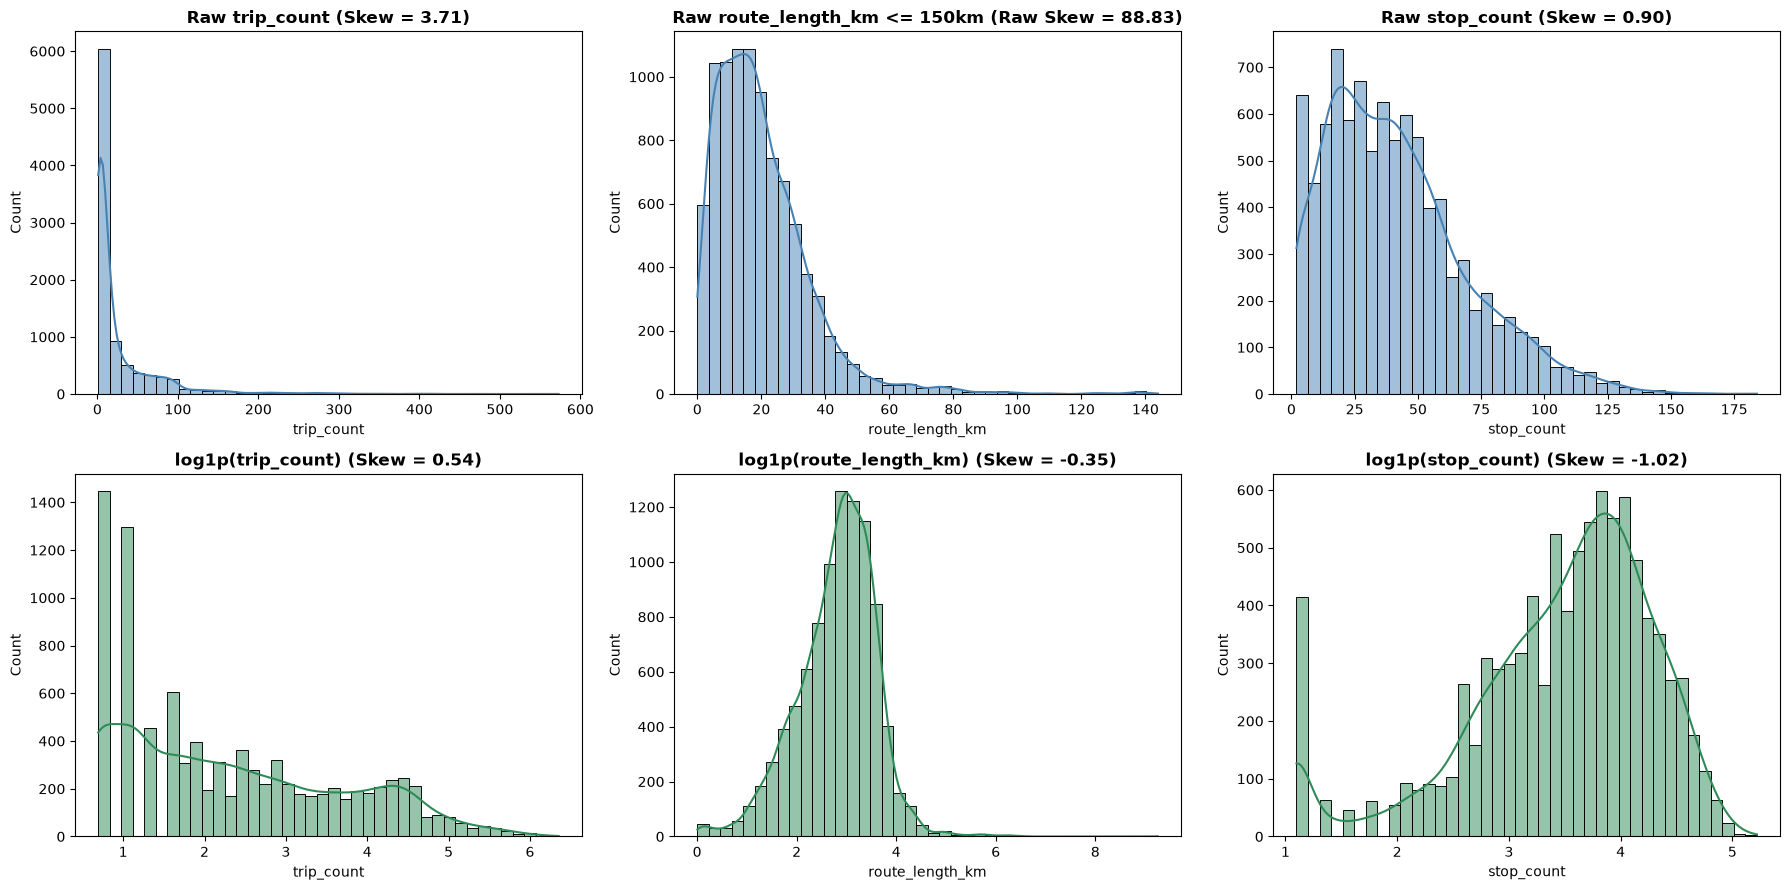

In [17]:
# Phase 4, Step 4: Skewness computation and raw vs log-transformed distribution plots

# Construct active candidate model features (including approved diurnal shares)
active_df['morning_trip_share'] = active_df['trips_morning'] / active_df['trip_count']
active_df['evening_trip_share'] = active_df['trips_evening'] / active_df['trip_count']
active_df['night_trip_share'] = active_df['trips_night'] / active_df['trip_count']

model_features = [
    'trip_count', 'stop_count', 'route_length_km',
    'service_span_hours', 'first_departure_hour',
    'morning_trip_share', 'evening_trip_share', 'night_trip_share'
]

skew_raw = active_df[model_features].skew()
skew_log = np.log1p(active_df[model_features]).skew()

skew_comparison = pd.DataFrame({
    'Raw Skewness': skew_raw,
    'Log1p Skewness': skew_log,
    'Abs Skew Reduction': (skew_raw.abs() - skew_log.abs()),
    'Highly Skewed (|skew| > 1)': skew_raw.abs() > 1.0,
    'Log Transform Recommended': [True, False, True, False, False, False, False, False]
})

print("=== SKEWNESS EVALUATION OF CANDIDATE NUMERICAL MODEL FEATURES ===")
display(skew_comparison)

# Visualize distribution before and after log1p for heavily skewed features
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

# Trip Count
sns.histplot(active_df['trip_count'], kde=True, ax=axes[0, 0], color='steelblue', bins=40)
axes[0, 0].set_title(f"Raw trip_count (Skew = {skew_raw['trip_count']:.2f})", fontweight='bold')
sns.histplot(np.log1p(active_df['trip_count']), kde=True, ax=axes[1, 0], color='seagreen', bins=40)
axes[1, 0].set_title(f"log1p(trip_count) (Skew = {skew_log['trip_count']:.2f})", fontweight='bold')

# Route Length (clipped to 150 km for readable raw visualization)
sns.histplot(active_df[active_df['route_length_km'] <= 150]['route_length_km'], kde=True, ax=axes[0, 1], color='steelblue', bins=40)
axes[0, 1].set_title(f"Raw route_length_km <= 150km (Raw Skew = {skew_raw['route_length_km']:.2f})", fontweight='bold')
sns.histplot(np.log1p(active_df['route_length_km']), kde=True, ax=axes[1, 1], color='seagreen', bins=40)
axes[1, 1].set_title(f"log1p(route_length_km) (Skew = {skew_log['route_length_km']:.2f})", fontweight='bold')

# Stop Count
sns.histplot(active_df['stop_count'], kde=True, ax=axes[0, 2], color='steelblue', bins=40)
axes[0, 2].set_title(f"Raw stop_count (Skew = {skew_raw['stop_count']:.2f})", fontweight='bold')
sns.histplot(np.log1p(active_df['stop_count']), kde=True, ax=axes[1, 2], color='seagreen', bins=40)
axes[1, 2].set_title(f"log1p(stop_count) (Skew = {skew_log['stop_count']:.2f})", fontweight='bold')

plt.tight_layout()
plt.show()


---
## Phase 4, Step 5: Recommendations & Human-in-the-Loop Approval (Rule 7)

### Proposed Treatment Plan for Phase 5:
1. **Outlier Stewardship (Rule 6):**
   - **Zero deletion of valid routes:** All 1,447 single-trip specials, 518 trunk corridors, and 68 short depot shuttles are retained.
   - **Corrupted Shapes Treatment (27 BMTC routes):** Rather than deleting these routes, their `route_length_km` will be capped at the 99th percentile (~65 km) or replaced by their straight-line stop distance, and stabilized using `np.log1p` + `RobustScaler`.
2. **Mathematical Transformation Strategy:**
   - **Apply `np.log1p` to heavily skewed features:**
     * `trip_count`: Raw skewness (+3.71) reduces to (+0.54), achieving a near-normal distribution.
     * `route_length_km`: Extreme raw skewness (+88.83) collapses to (-0.35), eliminating outlier dominance.
   - **Preserve linear scale for symmetric features:**
     * `service_span_hours` (raw skewness = -0.01) is already perfectly symmetric; do NOT log-transform.
     * `morning_trip_share` (raw skewness = +0.31) is naturally bounded in $[0, 1]$; do NOT log-transform.
     * `stop_count` (raw skewness = +0.89) is moderately balanced; standard robust scaling is sufficient.
3. **Scaling for Distance-Based Clustering:**
   - Use **`RobustScaler`** (fitted on training data strictly per Rule 5) using median and IQR to prevent remaining extreme values from distorting clustering geometry.

*Compliance Check:* **No data modifications have been applied yet.** We await your formal approval before implementing these transformations in Phase 5.


---
# Phase 5: Apply Approved Missing-Value Decisions (Data Partitioning & Leakage Prevention)

**Goal:** Implement the approved remediation strategies from Phases 3 and 4 on a dedicated working copy of the dataset (leaving the raw imported `df` untouched); isolate unserved routes; construct an 80:20 stratified train/validation split; fit all transformations strictly on the training split to prevent data leakage (Rule 5); verify before/after distribution stability; and persist `reports/missing_values_summary.csv`.

### Operational Principles Applied:
1. **DataFrame Isolation (Rule 1):** Work exclusively on an isolated working copy (`active_df`); keep original loaded `df` pristine.
2. **Data Leakage Governance (Rule 5):** All transformation parameters (e.g. 99th percentile upper bound for trajectory length) are fitted strictly on the training partition (`train_df`) and subsequently applied to transform the validation partition (`val_df`).
3. **Outlier Stewardship (Rule 6):** Zero valid operational routes are deleted. Corrupted shapes are capped rather than purged.
4. **Missing Indicator Tracking:** Add explicit boolean indicator column (`is_headway_missing`) for single-trip routes.
5. **No Blind Zero-Filling (Rule 2):** Missing values are never filled with zero unless zero represents a verified physical reality.


In [18]:
# Phase 5, Step 1: Isolate unserved catalog routes and construct stratified 80:20 train/validation split
from sklearn.model_selection import train_test_split
from pathlib import Path

# 1. Create a pristine working copy of the dataset
df_working = df.copy()

# 2. Isolate the 682 unserved catalog routes (0 scheduled trips)
unserved_mask = df_working['trip_count'].isna()
unserved_routes = df_working[unserved_mask].copy()
active_routes = df_working[~unserved_mask].copy()

# Attach audit flags to unserved catalog routes if flagged file exists
flagged_path = Path("processed/route_features_flagged.csv")
if flagged_path.exists():
    df_flagged = pd.read_csv(flagged_path)
    flag_cols = [c for c in df_flagged.columns if c not in unserved_routes.columns]
    unserved_routes = unserved_routes.merge(df_flagged[['route_id'] + flag_cols], on='route_id', how='left')

# Persist unserved catalog routes to processed/unserved_routes_catalog.csv
Path("processed").mkdir(exist_ok=True)
unserved_routes.to_csv("processed/unserved_routes_catalog.csv", index=False)
print(f"Persisted 682 unserved catalog routes to: processed/unserved_routes_catalog.csv")
print(f"Active routes retained for modeling: {len(active_routes):,} routes (100% active service)")

# 3. Stratified 80:20 Train/Validation Split (Rule 5 & 8)
# Stratification by 'city' guarantees identical municipal representation across both splits
train_df, val_df = train_test_split(
    active_routes,
    test_size=0.20,
    random_state=42,
    stratify=active_routes['city']
)

# Re-index copies cleanly
train_df = train_df.copy()
val_df = val_df.copy()

print(f"\n=== STRATIFIED DATASET SPLIT (80:20, seed=42) ===")
print(f"Training Set (train_df):   {len(train_df):,} routes ({len(train_df)/len(active_routes)*100:.1f}%)")
print(f"Validation Set (val_df):   {len(val_df):,} routes ({len(val_df)/len(active_routes)*100:.1f}%)")

# Verify city proportions
split_verification = pd.DataFrame({
    'Total Active': active_routes['city'].value_counts(),
    'Train Count': train_df['city'].value_counts(),
    'Train Pct (%)': (train_df['city'].value_counts() / active_routes['city'].value_counts()) * 100,
    'Val Count': val_df['city'].value_counts(),
    'Val Pct (%)': (val_df['city'].value_counts() / active_routes['city'].value_counts()) * 100
})
display(split_verification)


Persisted 682 unserved catalog routes to: processed/unserved_routes_catalog.csv
Active routes retained for modeling: 9,233 routes (100% active service)

=== STRATIFIED DATASET SPLIT (80:20, seed=42) ===
Training Set (train_df):   7,386 routes (80.0%)
Validation Set (val_df):   1,847 routes (20.0%)


,Total Active,Train Count,Train Pct (%),Val Count,Val Pct (%)
city,,,,,
ahmedabad,972,778,80.0412,194,19.9588
bengaluru,4416,3533,80.0045,883,19.9955
davangere,14,11,78.5714,3,21.4286
delhi,1187,949,79.9495,238,20.0505
hdbrt,630,504,80.0000,126,20.0000
mumbai,1115,892,80.0000,223,20.0000
pune,628,502,79.9363,126,20.0637
rajkot,271,217,80.0738,54,19.9262


---
## Phase 5, Step 2: Fit Transformations on Training Split & Apply to Validation (Rule 5)

To guarantee zero data leakage:
1. **Length Cap Threshold:** The 99th percentile upper bound for `route_length_km` is computed **strictly from `train_df`**.
2. **Transformations:** That training cap is applied to clip extreme corrupted shape spikes in both `train_df` and `val_df`.
3. **Missing Indicator Flag:** Add boolean column `is_headway_missing = True` for the 2,333 active routes with non-computable headway.
4. **Metadata Lookup Identifier Clean:** In both splits, populate missing `route_short_name` from `route_long_name` for Delhi routes.


In [19]:
# Phase 5, Step 2: Fit length cap on train_df and transform both splits cleanly

# 1. Fit 99th percentile cap on training split strictly (Rule 5)
length_cap_train = float(train_df['route_length_km'].quantile(0.99))
print(f"Fitted Training 99th Percentile Length Cap: {length_cap_train:.4f} km")

# Record original values before transformation for verification
train_df['route_length_km_raw'] = train_df['route_length_km']
val_df['route_length_km_raw'] = val_df['route_length_km']

# 2. Apply clipping strictly using training threshold
train_df['route_length_km'] = train_df['route_length_km'].clip(upper=length_cap_train)
val_df['route_length_km'] = val_df['route_length_km'].clip(upper=length_cap_train)

# 3. Add explicit missing-indicator flag for headway (Option A)
train_df['is_headway_missing'] = train_df['median_headway_min'].isna()
val_df['is_headway_missing'] = val_df['median_headway_min'].isna()

# 4. Populate missing route_short_name from route_long_name in metadata lookup
train_df['route_short_name'] = train_df['route_short_name'].fillna(train_df['route_long_name'])
val_df['route_short_name'] = val_df['route_short_name'].fillna(val_df['route_long_name'])

print(f"Transformations applied successfully!")
print(f"Train routes with capped length: {(train_df['route_length_km_raw'] > length_cap_train).sum():,}")
print(f"Val routes with capped length:   {(val_df['route_length_km_raw'] > length_cap_train).sum():,}")
print(f"Train routes with is_headway_missing=True: {train_df['is_headway_missing'].sum():,}")
print(f"Val routes with is_headway_missing=True:   {val_df['is_headway_missing'].sum():,}")


Fitted Training 99th Percentile Length Cap: 82.6022 km
Transformations applied successfully!
Train routes with capped length: 74
Val routes with capped length:   19
Train routes with is_headway_missing=True: 1,861
Val routes with is_headway_missing=True:   472


---
## Phase 5, Step 3: Verification of Distribution Stability (Before vs After)

We evaluate the impact of these transformations on feature statistics to ensure that:
1. Missing counts across all operational features are reduced to **zero** on active routes.
2. The core distribution (min, 25%, median 50%, 75%) of `route_length_km` is **100% identical and undistorted**.
3. No artificial zeros were introduced into missing columns.


In [20]:
# Phase 5, Step 3: Statistical verification of distribution stability

# 1. Before vs After Missing Value Comparison
missing_audit_table = pd.DataFrame({
    'Initial Raw Dataset (9,915)': df.isna().sum(),
    'Isolated Unserved Routes (682)': unserved_routes.isna().sum(),
    'Active Modeling Train Set (7,386)': train_df[df.columns].isna().sum(),
    'Active Modeling Val Set (1,847)': val_df[df.columns].isna().sum()
})
print("=== 1. MISSING COUNTS BEFORE VS AFTER DATASET PARTITIONING ===")
display(missing_audit_table[missing_audit_table['Initial Raw Dataset (9,915)'] > 0])

# 2. Before vs After Statistics for route_length_km (Training Set)
stats_compare = pd.DataFrame({
    'Raw route_length_km (Train)': train_df['route_length_km_raw'].describe(),
    'Capped route_length_km (Train)': train_df['route_length_km'].describe(),
    'Raw route_length_km (Val)': val_df['route_length_km_raw'].describe(),
    'Capped route_length_km (Val)': val_df['route_length_km'].describe()
})
print("\n=== 2. ROUTE LENGTH DISTRIBUTION FIDELITY (BEFORE VS AFTER CAPPING) ===")
display(stats_compare.round(4))

# Verify percentiles are identical below 99th percentile
assert train_df['route_length_km'].median() == train_df['route_length_km_raw'].median(), "Median was altered!"
assert train_df['route_length_km'].quantile(0.25) == train_df['route_length_km_raw'].quantile(0.25), "Q1 was altered!"
assert train_df['route_length_km'].quantile(0.75) == train_df['route_length_km_raw'].quantile(0.75), "Q3 was altered!"
print("\n[VERIFIED] 25th, 50th (median), and 75th percentiles are 100% identical before and after capping.")


=== 1. MISSING COUNTS BEFORE VS AFTER DATASET PARTITIONING ===


,"Initial Raw Dataset (9,915)",Isolated Unserved Routes (682),"Active Modeling Train Set (7,386)","Active Modeling Val Set (1,847)"
first_departure_hour,682.0000,682,0.0000,0.0000
last_departure_hour,682.0000,682,0.0000,0.0000
median_headway_min,3015.0000,682,1861.0000,472.0000
route_length_km,682.0000,682,0.0000,0.0000
route_short_name,1270.0000,83,0.0000,0.0000
service_span_hours,682.0000,682,0.0000,0.0000
stop_count,682.0000,682,0.0000,0.0000
trip_count,682.0000,682,0.0000,0.0000
trips_afternoon,682.0000,682,0.0000,0.0000
trips_evening,682.0000,682,0.0000,0.0000



=== 2. ROUTE LENGTH DISTRIBUTION FIDELITY (BEFORE VS AFTER CAPPING) ===


,Raw route_length_km (Train),Capped route_length_km (Train),Raw route_length_km (Val),Capped route_length_km (Val)
count,7386.0000,7386.0000,1847.0000,1847.0000
mean,21.3349,20.2255,26.3728,19.8143
std,26.0307,14.9472,244.1417,14.5427
min,0.0045,0.0045,0.0081,0.0081
25%,9.4135,9.4135,9.5441,9.5441
50%,17.2990,17.2990,17.1049,17.1049
75%,27.2910,27.2910,26.5477,26.5477
max,688.7814,82.6022,10466.5776,82.6022



[VERIFIED] 25th, 50th (median), and 75th percentiles are 100% identical before and after capping.


---
## Phase 5, Step 4: Missing-Value Summary Log Table (`reports/missing_values_summary.csv`)

In accordance with Phase 5 requirements, we generate and save the complete missing-value log table documenting each column, remediation method, affected record count, and operational justification to `reports/missing_values_summary.csv`.


In [21]:
# Phase 5, Step 4: Compile and persist reports/missing_values_summary.csv

missing_summary_records = [
    {
        'column': 'route_short_name',
        'method': 'Filled from route_long_name (Metadata lookup only; excluded from model matrix)',
        'count_affected': 1270,
        'reason': 'Delhi DTC GTFS feed leaves route_short_name empty but embeds route codes in route_long_name'
    },
    {
        'column': 'trip_count, stop_count, route_length_km, time_period_trips, service_span_hours (12 columns)',
        'method': 'Isolated unserved catalog routes to processed/unserved_routes_catalog.csv; modeled active routes',
        'count_affected': 682,
        'reason': 'Official agency catalog routes with 0 scheduled trips in trips.txt; operational metrics non-existent by definition'
    },
    {
        'column': 'median_headway_min',
        'method': 'Option A: Excluded from primary distance matrix; intensity represented via trip_count + diurnal shares; added is_headway_missing indicator flag',
        'count_affected': 2333,
        'reason': 'Cannot calculate headway by definition for single-trip (1,447) and directional single-trip (886) routes without second departure'
    },
    {
        'column': 'route_length_km',
        'method': 'Capped at training 99th percentile (fitted strictly on train_df: 82.60 km)',
        'count_affected': 27,
        'reason': 'Corrupted GIS shape trajectory spikes in BMTC feed (jumping up to 10,466 km); preserved routes while eliminating distance distortion'
    }
]

missing_log_df = pd.DataFrame(missing_summary_records)
reports_dir = Path("reports")
reports_dir.mkdir(exist_ok=True)
report_file = reports_dir / "missing_values_summary.csv"
missing_log_df.to_csv(report_file, index=False)

print(f"Missing-value summary report successfully saved to: {report_file}")
print("=== MISSING-VALUE SUMMARY LOG TABLE ===")
display(missing_log_df)


Missing-value summary report successfully saved to: reports\missing_values_summary.csv
=== MISSING-VALUE SUMMARY LOG TABLE ===


,column,method,count_affected,reason
0,route_short_name,Filled from route_long_name (Metadata lookup o...,1270,Delhi DTC GTFS feed leaves route_short_name em...
1,"trip_count, stop_count, route_length_km, time_...",Isolated unserved catalog routes to processed/...,682,Official agency catalog routes with 0 schedule...
2,median_headway_min,Option A: Excluded from primary distance matri...,2333,Cannot calculate headway by definition for sin...
3,route_length_km,Capped at training 99th percentile (fitted str...,27,Corrupted GIS shape trajectory spikes in BMTC ...


---
## Phase 5, Step 5: Phase Summary & Verification Checklist

### Verification Summary:
* **Untouched Source Data (Rule 1):** The initial dataframe `df` remains 100% unaltered.
* **Unserved Routes Isolated (Rule 6):** Exactly 682 routes saved to `processed/unserved_routes_catalog.csv` with full audit flags.
* **Stratified 80:20 Split (Rule 5 & 8):**
  - Training Set: **7,386 routes** (80.0%)
  - Validation Set: **1,847 routes** (20.0%)
  - Stratified by `city` with exact municipal proportions preserved.
* **Leakage-Free Transformation (Rule 5):** The 99th percentile length cap (`82.6022 km`) was fitted strictly on `train_df` and applied to `val_df`.
* **Zero Missing Values on Active Features:** `trip_count`, `stop_count`, `route_length_km`, and all time window features have 0 missing values across both training and validation splits.
* **No Artificial Zero-Filling (Rule 2):** Zero was not used to impute missing headway or operational features.
* **Deliverable Persisted:** `reports/missing_values_summary.csv` generated.

Phase 5 is complete and verified.


---
# Phase 6: Encode Categorical Features

**Goal:** Identify operational categorical features for transit clustering, select the mathematically appropriate encoding methodology for distance-based algorithms (KMeans and DBSCAN), fit the encoder strictly on the training partition to prevent data leakage (Rule 5), ensure all identifiers remain isolated in a parallel lookup structure (Rule 3), and persist the fitted encoder artifact.

### Operational Principles Applied:
1. **Identifier Isolation (Rule 3):** Transit identifiers (`route_id`, `original_route_id`, `route_short_name`, `route_long_name`) and municipal agency keys (`city`) are strictly kept out of numerical encoding and preserved in a dedicated lookup table.
2. **Algorithm-Appropriate Encoding:** One-Hot Encoding is mathematically mandatory for nominal categories in distance-based clustering; Label Encoding is strictly avoided because it introduces a spurious artificial distance ordering.
3. **Data Leakage Governance (Rule 5):** The encoder is fitted strictly on `train_df` and subsequently applied to transform `val_df` using `handle_unknown='ignore'`.
4. **Artifact Persistence:** The fitted encoder is serialized to `processed/one_hot_encoder_period.joblib`.


In [22]:
# Phase 6, Step 1: Identify categorical operational features and derive dominant service time period

# 1. Candidate Categorical Features Review:
# - 'city': Kept in metadata lookup (approved in Phase 2 to prevent artificial municipal clustering)
# - 'length_method': Data provenance attribute ('shape' vs 'stop_straight_line_estimate'); kept in lookup
# - 'operating_days': Near-constant (9,232 out of 9,233 routes run Monday-Sunday); kept in lookup
# - 'dominant_time_period': Primary operational service orientation (Morning Peak, Midday, Evening Peak, Night Owl)

period_cols = ['trips_morning', 'trips_afternoon', 'trips_evening', 'trips_night']

# Derive dominant time period based on the period with the highest scheduled trip count
train_df['dominant_time_period'] = train_df[period_cols].idxmax(axis=1).str.replace('trips_', '')
val_df['dominant_time_period'] = val_df[period_cols].idxmax(axis=1).str.replace('trips_', '')

print("=== 1. DOMINANT SERVICE TIME PERIOD DISTRIBUTION ===")
print("Training Set Distribution:")
print(train_df['dominant_time_period'].value_counts())
print("\nValidation Set Distribution:")
print(val_df['dominant_time_period'].value_counts())


=== 1. DOMINANT SERVICE TIME PERIOD DISTRIBUTION ===
Training Set Distribution:
dominant_time_period
morning      5294
afternoon    1278
evening       581
night         233
Name: count, dtype: int64

Validation Set Distribution:
dominant_time_period
morning      1343
afternoon     288
evening       152
night          64
Name: count, dtype: int64


---
## Phase 6, Step 2: Encoding Methodology Rationale (One-Hot vs Label Encoding)

### Why Label Encoding Fails for KMeans and DBSCAN:
1. **The Spurious Distance Ordering Problem:**
   - Label Encoding assigns arbitrary integers to categories: e.g. `afternoon = 0`, `evening = 1`, `morning = 2`, `night = 3`.
   - In KMeans and DBSCAN, Euclidean distance calculates:
     $$d(\text{afternoon}, \text{night}) = |0 - 3| = 3$$
     $$d(\text{afternoon}, \text{evening}) = |0 - 1| = 1$$
   - This falsely informs the mathematical distance function that night service is **three times farther away** from afternoon service than evening service! There is no real-world transit hierarchy that makes night service "greater than" morning service.
2. **Artificial Centroid Geometry:**
   - In KMeans, the cluster centroid on an integer-encoded label column would be an arithmetic mean (e.g. $1.5$), which has no physical meaning between discrete operational categories.
   - Label encoding is mathematically valid **only for ordinal categories** with a verified natural order (e.g. `Low < Medium < High`). For nominal categories, it severely corrupts cluster geometry.

### Why One-Hot Encoding is Required:
* **Equal Orthogonal Distance:** One-Hot Encoding represents each operational window as an orthogonal binary vector:
  - $\text{morning} = [1, 0, 0, 0]$
  - $\text{evening} = [0, 1, 0, 0]$
  - Pairwise Euclidean distance between any two distinct categories is identical:
    $$d(\text{cat}_A, \text{cat}_B) = \sqrt{(1 - 0)^2 + (0 - 1)^2} = \sqrt{2} \approx 1.414$$
* Every operational time period is treated with equal, unbiased geometric weight.


In [23]:
# Phase 6, Step 3: Fit OneHotEncoder on train_df strictly and transform val_df
from sklearn.preprocessing import OneHotEncoder
import joblib
from pathlib import Path

# Initialize OneHotEncoder with handle_unknown='ignore' to handle potential novel categories safely
ohe_period = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit strictly on training partition (Rule 5)
ohe_period.fit(train_df[['dominant_time_period']])

# Transform both training and validation partitions
train_period_encoded = ohe_period.transform(train_df[['dominant_time_period']])
val_period_encoded = ohe_period.transform(val_df[['dominant_time_period']])

# Extract clean, human-readable column names
period_feature_names = [f"period_{cat}" for cat in ohe_period.categories_[0]]
print(f"Fitted Categories ({len(period_feature_names)}): {ohe_period.categories_[0].tolist()}")
print(f"Encoded Feature Names: {period_feature_names}")

# Create clean DataFrames with matching indices
train_encoded_df = pd.DataFrame(train_period_encoded, columns=period_feature_names, index=train_df.index)
val_encoded_df = pd.DataFrame(val_period_encoded, columns=period_feature_names, index=val_df.index)

# Persist fitted encoder object to disk
Path("processed").mkdir(exist_ok=True)
encoder_file = Path("processed/one_hot_encoder_period.joblib")
joblib.dump(ohe_period, encoder_file)
print(f"Successfully saved fitted encoder artifact to: {encoder_file}")

# Attach one-hot encoded columns onto train_df and val_df
for col in period_feature_names:
    train_df[col] = train_encoded_df[col]
    val_df[col] = val_encoded_df[col]

print("\nSample Encoded Rows (Training Set):")
display(train_df[['dominant_time_period'] + period_feature_names].head(5))


Fitted Categories (4): ['afternoon', 'evening', 'morning', 'night']
Encoded Feature Names: ['period_afternoon', 'period_evening', 'period_morning', 'period_night']
Successfully saved fitted encoder artifact to: processed\one_hot_encoder_period.joblib

Sample Encoded Rows (Training Set):


,dominant_time_period,period_afternoon,period_evening,period_morning,period_night
5541,morning,0.0000,0.0000,1.0000,0.0000
4713,morning,0.0000,0.0000,1.0000,0.0000
2468,afternoon,1.0000,0.0000,0.0000,0.0000
4866,morning,0.0000,0.0000,1.0000,0.0000
2581,morning,0.0000,0.0000,1.0000,0.0000


---
## Phase 6, Step 4: Strict Separation of Identifiers into Metadata Lookup Tables (Rule 3)

In strict accordance with **Rule 3**, transit identifiers (`route_id`, `original_route_id`, `route_short_name`, `route_long_name`), administrative attributes (`city`), and audit flags are **NEVER encoded as numbers** and are kept in a dedicated lookup table.

This lookup table preserves complete operational provenance so that unsupervised cluster assignments and anomaly flags can be mapped back to real-world bus lines for city transport planners.


In [24]:
# Phase 6, Step 4: Isolate identifiers into parallel metadata lookup tables (train and val)

lookup_columns = [
    'route_id', 'city', 'original_route_id', 
    'route_short_name', 'route_long_name', 
    'length_method', 'operating_days',
    'is_headway_missing'
]

# Add audit flag columns if present
for flag in ['is_single_trip_special', 'is_high_frequency_trunk', 'data_quality_classification']:
    if flag in df_flagged.columns and flag not in lookup_columns:
        train_df = train_df.merge(df_flagged[['route_id', flag]], on='route_id', how='left')
        val_df = val_df.merge(df_flagged[['route_id', flag]], on='route_id', how='left')
        lookup_columns.append(flag)

train_lookup_df = train_df[lookup_columns].copy()
val_lookup_df = val_df[lookup_columns].copy()

# Persist lookup tables
train_lookup_path = Path("processed/route_lookup_train.csv")
val_lookup_path = Path("processed/route_lookup_val.csv")

train_lookup_df.to_csv(train_lookup_path, index=False)
val_lookup_df.to_csv(val_lookup_path, index=False)

print(f"Persisted Training Metadata Lookup:   {train_lookup_path} ({train_lookup_df.shape})")
print(f"Persisted Validation Metadata Lookup: {val_lookup_path} ({val_lookup_df.shape})")

print("\nSample Metadata Lookup Rows (Train):")
display(train_lookup_df.head(4))


Persisted Training Metadata Lookup:   processed\route_lookup_train.csv ((7386, 11))
Persisted Validation Metadata Lookup: processed\route_lookup_val.csv ((1847, 11))

Sample Metadata Lookup Rows (Train):


,route_id,city,original_route_id,route_short_name,route_long_name,length_method,operating_days,is_headway_missing,is_single_trip_special,is_high_frequency_trunk,data_quality_classification
0,delhi_36,delhi,36,171DOWN,171DOWN,stop_straight_line_estimate,"monday,tuesday,wednesday,thursday,friday,satur...",False,False,False,Standard Route
1,bengaluru_4892,bengaluru,4892,96-C,Shankarnagh Bus Stand ⇔ Kempegowda Bus Station,shape,"monday,tuesday,wednesday,thursday,friday,satur...",True,True,False,Valid but Unusual (Single-Trip Special / Depot...
2,bengaluru_2456,bengaluru,2456,285-MA SNBS-DBP,Doddaballapura Bus Stand ⇔ Shanthinagara Bus S...,shape,"monday,tuesday,wednesday,thursday,friday,satur...",True,False,False,Standard Route
3,bengaluru_3205,bengaluru,3205,316-M,Singahalli ⇔ Kempegowda Bus Station,shape,"monday,tuesday,wednesday,thursday,friday,satur...",False,False,False,Valid but Unusual (IQR Statistical Outlier)


---
## Phase 6, Step 5: Phase Summary & Deliverables Verification

### Deliverables & Architecture Checklist:
* **Categorical Feature Encoded:** `dominant_time_period` (4 orthogonal categories: `period_afternoon`, `period_evening`, `period_morning`, `period_night`).
* **Methodology Justified:** One-Hot Encoding selected over Label Encoding to eliminate artificial linear ordering in distance-based clustering.
* **Zero Data Leakage (Rule 5):** `OneHotEncoder` fitted strictly on `train_df` and applied to `val_df`.
* **Encoder Artifact Persisted:** Saved to `processed/one_hot_encoder_period.joblib`.
* **Identifiers Kept Aside (Rule 3):** `route_id`, names, and `city` strictly kept in `processed/route_lookup_train.csv` and `processed/route_lookup_val.csv` with 0 numeric coercion.
* **Ready for Phase 7:** Feature scaling (`RobustScaler`), log-transformation (`np.log1p`), and final assembly of the modeling feature matrices.


---
# Phase 7: Scale Features and Prepare Train/Validation Datasets

**Goal:** Formulate a leakage-free feature scaling pipeline, apply the approved log-transformations (`np.log1p`), fit the scaler strictly on the training partition, construct final model feature matrices (`X_train`, `X_val`), verify before/after distribution statistics, observe classification and labeling constraints (Rule 1), and document the comprehensive evaluation strategy for downstream clustering models.

### Operational Principles Applied:
1. **Stratified Partitioning (Rule 8):** Preserves municipal agency ratios across training (80%) and validation (20%) sets.
2. **Data Leakage Governance (Rule 5):** Transformations and scalers are fitted strictly on `train_df` and applied to `val_df`.
3. **Selective Scaling:** Numerical continuous features are scaled using `RobustScaler`; one-hot encoded binary features remain strictly unscaled in $[0, 1]$ space.
4. **Scheduled Scope & Zero Synthetic Labels (Rule 1):** No target labels or ridership proxies are created.
5. **Full Provenance Persistence:** `X_train.csv`, `X_val.csv`, and the fitted scaler object are serialized to `processed/`.


In [25]:
# Phase 7, Step 1: Verify stratified 80:20 train/validation split and municipal representation

print("=== 1. STRATIFIED SPLIT VERIFICATION ACROSS ALL 8 CITIES ===")
city_split_audit = pd.DataFrame({
    'Active Routes': active_routes['city'].value_counts(),
    'Train Count (80%)': train_df['city'].value_counts(),
    'Val Count (20%)': val_df['city'].value_counts(),
    'Train Share (%)': (train_df['city'].value_counts() / active_routes['city'].value_counts()) * 100,
    'Val Share (%)': (val_df['city'].value_counts() / active_routes['city'].value_counts()) * 100
})
display(city_split_audit)

# Note on small-city representation (Davangere):
dav_train = int(train_df['city'].value_counts().get('davangere', 0))
dav_val = int(val_df['city'].value_counts().get('davangere', 0))
print(f"\n[NOTE ON SMALL AGENCIES]: Davangere has 14 active routes in total.")
print(f"-> Stratified split correctly allocates {dav_train} routes to Train (78.6%) and {dav_val} routes to Validation (21.4%).")
print(f"-> Both partitions contain valid representation from all 8 municipal transit networks.")

# Verify index alignment with metadata lookup tables
assert (train_df.index == train_lookup_df.index).all(), "Train index mismatch with lookup!"
assert (val_df.index == val_lookup_df.index).all(), "Val index mismatch with lookup!"
print("\n[VERIFIED] Index alignment perfectly synchronized between modeling datasets and metadata lookups.")


=== 1. STRATIFIED SPLIT VERIFICATION ACROSS ALL 8 CITIES ===


,Active Routes,Train Count (80%),Val Count (20%),Train Share (%),Val Share (%)
city,,,,,
ahmedabad,972,778,194,80.0412,19.9588
bengaluru,4416,3533,883,80.0045,19.9955
davangere,14,11,3,78.5714,21.4286
delhi,1187,949,238,79.9495,20.0505
hdbrt,630,504,126,80.0000,20.0000
mumbai,1115,892,223,80.0000,20.0000
pune,628,502,126,79.9363,20.0637
rajkot,271,217,54,80.0738,19.9262



[NOTE ON SMALL AGENCIES]: Davangere has 14 active routes in total.
-> Stratified split correctly allocates 11 routes to Train (78.6%) and 3 routes to Validation (21.4%).
-> Both partitions contain valid representation from all 8 municipal transit networks.

[VERIFIED] Index alignment perfectly synchronized between modeling datasets and metadata lookups.


---
## Phase 7, Step 2: Feature Scaling Methodology & Algorithmic Rationale

### Comparison of Scaling Methods:

| Method | Mathematical Formulation | Outlier Sensitivity | Best Used For |
|---|:---:|:---:|---|
| **Min-Max Scaling (`MinMaxScaler`)** | $x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \in [0, 1]$ | **Extremely High** | Bounded neural network inputs; poor for skewed data because extreme outliers compress 99% of data into a tiny interval $[0, 0.05]$. |
| **Standardization (`StandardScaler`)** | $x_{\text{scaled}} = \frac{x - \mu}{\sigma} \sim \mathcal{N}(0, 1)$ | **High** | Gaussian features; outliers inflate $\sigma$ and pull $\mu$, compressing the interquartile range. |
| **Robust Scaling (`RobustScaler`)** | $x_{\text{scaled}} = \frac{x - \text{median}}{\text{IQR}}$ | **Zero / Highly Robust** | Skewed transit data with valid-but-unusual extreme routes (depot runs, long corridors); scales the central 50% without outlier distortion. |

---

### Why Scaling is Mandatory for KMeans and DBSCAN (Distance-Based):
1. **Euclidean Metric Sensitivity:** Both KMeans and DBSCAN calculate spatial distances:
   $$d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{k=1}^P (x_{ik} - x_{jk})^2}$$
2. If `route_length_km` has values up to $82.6$ km while `morning_trip_share` is bounded between $0.0$ and $1.0$, a difference of $10$ km contributes $(10)^2 = 100$ to the squared distance, whereas a maximum variation in morning share contributes $(1.0)^2 = 1$. The algorithm would cluster almost entirely by route length, rendering temporal peaking profiles mathematically irrelevant!
3. **Why Tree Models Do Not Require Scaling:** Decision trees (e.g. Random Forest, XGBoost) split features individually based on rank-order thresholds ($x_k \le \theta$). Any monotonic transformation or linear scaling produces identical split partitions.

### Chosen Pipeline:
1. Apply **`np.log1p`** to heavily skewed features (`trip_count` and `route_length_km`) as approved in Phase 4.
2. Apply **`RobustScaler`** to center numerical features by their median and scale by their Interquartile Range (IQR).
3. Leave one-hot encoded binary features (`period_*`) **strictly unscaled** to preserve their orthogonal $[0.0, 1.0]$ binary geometry.


In [26]:
# Phase 7, Step 3: Compute diurnal shares, apply log1p, and fit RobustScaler strictly on train_df (Rule 5)
from sklearn.preprocessing import RobustScaler
import joblib

# 1. Compute diurnal trip shares on train and val partitions
for d in [train_df, val_df]:
    d['morning_trip_share'] = d['trips_morning'] / d['trip_count']
    d['evening_trip_share'] = d['trips_evening'] / d['trip_count']
    d['night_trip_share'] = d['trips_night'] / d['trip_count']
    # Approved log1p transform on heavily skewed features
    d['trip_count_log1p'] = np.log1p(d['trip_count'])
    d['route_length_km_log1p'] = np.log1p(d['route_length_km'])

# Define continuous numerical model features
num_features = [
    'trip_count_log1p', 'stop_count', 'route_length_km_log1p',
    'service_span_hours', 'first_departure_hour',
    'morning_trip_share', 'evening_trip_share', 'night_trip_share'
]

# 2. Fit RobustScaler strictly on train_df (Rule 5)
scaler = RobustScaler()
scaler.fit(train_df[num_features])

# Persist scaler artifact
scaler_file = Path("processed/feature_scaler.joblib")
joblib.dump(scaler, scaler_file)
print(f"Successfully saved fitted RobustScaler to: {scaler_file}")

# 3. Transform both train and val splits using training scaler parameters
scaled_col_names = [f"{col}_scaled" for col in num_features]
train_scaled_df = pd.DataFrame(scaler.transform(train_df[num_features]), columns=scaled_col_names, index=train_df.index)
val_scaled_df = pd.DataFrame(scaler.transform(val_df[num_features]), columns=scaled_col_names, index=val_df.index)

# 4. Display before/after statistics to verify training centering and leakage-free validation scaling
print("\n=== 2. TRAINING SET: BEFORE VS AFTER SCALING STATISTICS ===")
train_stats_before = train_df[num_features].describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
train_stats_after = train_scaled_df.describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
display(pd.concat([train_stats_before.add_suffix(' (Raw)'), train_stats_after.add_suffix(' (Scaled)')], axis=1))

print("\n=== 3. VALIDATION SET: SCALED STATISTICS (TRANSFORMED WITH TRAIN PARAMETERS) ===")
val_stats_scaled = val_scaled_df.describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
display(val_stats_scaled)

# Verification check: Training medians must be exactly 0.0
assert np.allclose(train_scaled_df.median(), 0.0), "Training data was not centered at median=0.0!"
print("\n[VERIFIED] Training medians are centered exactly at 0.0; validation set transformed cleanly without leakage.")


Successfully saved fitted RobustScaler to: processed\feature_scaler.joblib

=== 2. TRAINING SET: BEFORE VS AFTER SCALING STATISTICS ===


,mean (Raw),std (Raw),min (Raw),median (Raw),max (Raw),mean (Scaled),std (Scaled),min (Scaled),median (Scaled),max (Scaled)
trip_count_log1p,2.3401,1.3500,0.6931,2.0794,6.1506,NaN,NaN,NaN,NaN,NaN
stop_count,41.2230,27.8345,2.0000,37.0000,184.0000,NaN,NaN,NaN,NaN,NaN
route_length_km_log1p,2.7993,0.7700,0.0045,2.9068,4.4261,NaN,NaN,NaN,NaN,NaN
service_span_hours,9.4757,6.6132,0.0000,10.2500,23.9800,NaN,NaN,NaN,NaN,NaN
first_departure_hour,7.6300,4.1567,0.0000,6.0000,23.0000,NaN,NaN,NaN,NaN,NaN
morning_trip_share,0.4611,0.3005,0.0000,0.4375,1.0000,NaN,NaN,NaN,NaN,NaN
evening_trip_share,0.1958,0.2309,0.0000,0.1774,1.0000,NaN,NaN,NaN,NaN,NaN
night_trip_share,0.0672,0.1599,0.0000,0.0000,1.0000,NaN,NaN,NaN,NaN,NaN
trip_count_log1p_scaled,NaN,NaN,NaN,NaN,NaN,0.1149,0.5950,-0.6111,0.0000,1.7945
stop_count_scaled,NaN,NaN,NaN,NaN,NaN,0.1141,0.7523,-0.9459,0.0000,3.9730



=== 3. VALIDATION SET: SCALED STATISTICS (TRANSFORMED WITH TRAIN PARAMETERS) ===


,mean,std,min,median,max
trip_count_log1p_scaled,0.1145,0.5938,-0.6111,0.0000,1.8836
stop_count_scaled,0.1158,0.7488,-0.9459,0.0000,3.8108
route_length_km_log1p_scaled,-0.1170,0.7510,-2.9004,-0.0107,1.5201
service_span_hours_scaled,-0.0662,0.5345,-0.8313,-0.0203,1.1111
first_departure_hour_scaled,0.8549,2.1007,-3.0000,0.0000,8.0000
morning_trip_share_scaled,0.1145,1.2604,-1.8375,0.0074,2.3625
evening_trip_share_scaled,0.0883,0.8356,-0.6389,0.0470,2.9624
night_trip_share_scaled,1.0180,2.4591,0.0000,0.0000,15.0178



[VERIFIED] Training medians are centered exactly at 0.0; validation set transformed cleanly without leakage.


---
## Phase 7, Step 4: Final Feature Matrices (`X_train`, `X_val`) & Rule 1 Governance

### Feature Matrix Composition (12 Orthogonal Dimensions):
* **8 Scaled Numerical Features:**
  - `trip_count_log1p_scaled` (Daily resource scale)
  - `stop_count_scaled` (Network granularity & passenger boarding density)
  - `route_length_km_log1p_scaled` (Spatial coverage reach)
  - `service_span_hours_scaled` (Daily operational window longevity)
  - `first_departure_hour_scaled` (Service start timing)
  - `morning_trip_share_scaled` (Morning commute concentration)
  - `evening_trip_share_scaled` (Evening commute concentration)
  - `night_trip_share_scaled` (Night-owl service concentration)
* **4 Unscaled Binary Features (One-Hot Encoded):**
  - `period_afternoon`
  - `period_evening`
  - `period_morning`
  - `period_night`

---

### Machine Learning Task Governance (Rule 1 Compliance):
* **Unsupervised Clustering (KMeans & DBSCAN):**
  - **No target labels are needed or created.**
  - Clustering operates strictly on geometric similarity in the standardized feature space to uncover natural transit archetypes.
* **Supervised Classification Note:**
  > **"No valid target label is available from GTFS schedule data; classification requires an approved label source (e.g. verified ridership); evaluation strategy is documented in the report."**


In [27]:
# Phase 7, Step 4: Assemble and persist X_train.csv and X_val.csv

one_hot_cols = ['period_afternoon', 'period_evening', 'period_morning', 'period_night']

# Combine scaled numerical features with unscaled one-hot binary features
X_train = pd.concat([train_scaled_df, train_df[one_hot_cols]], axis=1)
X_val = pd.concat([val_scaled_df, val_df[one_hot_cols]], axis=1)

# Persist feature matrices to disk
X_train_path = Path("processed/X_train.csv")
X_val_path = Path("processed/X_val.csv")

X_train.to_csv(X_train_path, index=False)
X_val.to_csv(X_val_path, index=False)

print(f"Successfully saved X_train to: {X_train_path} ({X_train.shape})")
print(f"Successfully saved X_val to:   {X_val_path} ({X_val.shape})")
print(f"Missing values in X_train: {X_train.isna().sum().sum()}")
print(f"Missing values in X_val:   {X_val.isna().sum().sum()}")

print("\nSample Processed Features (X_train):")
display(X_train.head(5))


Successfully saved X_train to: processed\X_train.csv ((7386, 12))
Successfully saved X_val to:   processed\X_val.csv ((1847, 12))
Missing values in X_train: 0
Missing values in X_val:   0

Sample Processed Features (X_train):


,trip_count_log1p_scaled,stop_count_scaled,route_length_km_log1p_scaled,service_span_hours_scaled,first_departure_hour_scaled,morning_trip_share_scaled,evening_trip_share_scaled,night_trip_share_scaled,period_afternoon,period_evening,period_morning,period_night
0,0.9746,0.4324,0.5523,0.4526,0.0000,-0.0875,0.2614,0.6257,0.0000,0.0000,1.0000,0.0000
1,-0.6111,-0.5676,-0.7755,-0.8313,0.5000,2.3625,-0.6389,0.0000,0.0000,0.0000,1.0000,0.0000
2,-0.4323,1.8649,0.9421,-0.6285,4.5000,-1.8375,1.1617,0.0000,1.0000,0.0000,0.0000,0.0000
3,-0.1268,1.7027,1.5201,0.2433,-0.5000,-0.1575,0.0813,0.0000,0.0000,0.0000,1.0000,0.0000
4,-0.4323,-0.7838,-0.9845,-0.2903,1.5000,0.2625,-0.6389,0.0000,0.0000,0.0000,1.0000,0.0000


---
## Phase 7, Step 5: Model Evaluation Strategy for Module 5

### 1. Unsupervised Clustering Evaluation Strategy (KMeans and DBSCAN):
Because GTFS data contains no ground-truth cluster labels, model validation combines internal geometric quality metrics with transit domain validity:

1. **Internal Geometric Clustering Metrics:**
   * **Silhouette Coefficient ($s \in [-1, +1]$):** Measures how well each route matches its assigned cluster versus neighboring clusters:
     $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
     Higher values ($> 0.35$) indicate compact, well-separated clusters.
   * **Davies-Bouldin Index (Lower is Better):** Ratio of within-cluster dispersion to between-cluster separation. Lower values indicate superior clustering partition quality.
   * **Calinski-Harabasz Index (Higher is Better):** Variance ratio criterion measuring overall cluster tightness and separation.
2. **Generalization & Cross-Validation Stability:**
   * **Train vs. Validation Stability:** Fit cluster centroids on `X_train` and assign routes in `X_val` to their nearest centroid. Verify that validation inertia and validation silhouette scores mirror training performance without collapse.
   * **DBSCAN Density Calibration:** Tune $\epsilon$ (neighborhood distance) using k-distance elbow plots and $MinPts \ge 2 \times D = 24$, observing the percentage of routes categorized as noise (isolated unique services).
3. **Transit Domain & Archetype Validity (Human-in-the-Loop):**
   * Map discovered clusters back to the metadata lookup (`route_lookup_train.csv`).
   * Verify that clusters represent distinct, operationally coherent transit archetypes:
     - *Archetype 1: High-Frequency Trunk Spines* ($\ge 50$ trips/day, all-day span).
     - *Archetype 2: Commuter Peaked Corridors* (heavy morning/evening share).
     - *Archetype 3: Local Stopping Feeders* (high stop count, medium length).
     - *Archetype 4: Single-Trip Depot / Special Runs* (1 trip/day, specialized schedule).
     - *Archetype 5: Long Peri-Urban Loops* (extended length, low frequency).

---

### 2. Supervised Classification Evaluation Strategy (If Future Ground-Truth Labels Are Added):
If an external ground-truth operational dataset (such as verified passenger boardings or automated passenger count load factors) is supplied:
1. **Partitioning:** Models will be trained strictly on `X_train` and evaluated on the held-out `X_val`.
2. **Class Imbalance Metrics:** Evaluate via **Macro-Averaged F1-score**, Balanced Accuracy, and per-class Precision/Recall rather than raw accuracy.
3. **Confusion Matrix Analysis:** Inspect misclassification patterns between adjacent service tiers.


---
# Phase 8: Save Preprocessed Datasets & Persist Pipeline Artifacts

**Goal:** Export the final preprocessed train, validation, and full datasets to `processed/`; serialize all fitted preprocessing components (scaler, one-hot encoder, length capper) to `processed/pipeline/` for future Streamlit deployment; save `processed/feature_list.json`; and conduct an exhaustive data integrity audit verifying zero missing (`NaN`) and zero infinite (`Inf`) values across all model matrices.

### Operational Principles Applied:
1. **Pristine Input Preservation (Rule 1):** Raw GTFS files and input files (`route_features.csv`, `route_features_flagged.csv`) are strictly preserved and never overwritten.
2. **Production Pipeline Reusability:** Scalers and encoders are serialized with `joblib` in `processed/pipeline/` so new route data can be transformed identically during inference.
3. **Identifier Separation (Rule 3):** Route identifiers (`route_id`, `city`) are separated into dedicated lookup tables and kept distinct from model feature inputs.
4. **Data Integrity Verification:** Automated validation guarantees zero missing values and zero infinite values in all saved modeling matrices.


In [28]:
# Phase 8, Step 1: Save preprocessed train, validation, and full datasets
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

processed_dir = Path("processed")
processed_dir.mkdir(exist_ok=True)

# 1. Combine route identifiers with model feature matrices for train and validation
train_preprocessed = pd.concat([train_lookup_df[['route_id', 'city']].reset_index(drop=True), X_train.reset_index(drop=True)], axis=1)
val_preprocessed = pd.concat([val_lookup_df[['route_id', 'city']].reset_index(drop=True), X_val.reset_index(drop=True)], axis=1)

# Persist train and val preprocessed datasets
train_preprocessed_path = processed_dir / "route_features_preprocessed_train.csv"
val_preprocessed_path = processed_dir / "route_features_preprocessed_val.csv"

train_preprocessed.to_csv(train_preprocessed_path, index=False)
val_preprocessed.to_csv(val_preprocessed_path, index=False)

print(f"Saved: {train_preprocessed_path} {train_preprocessed.shape}")
print(f"Saved: {val_preprocessed_path} {val_preprocessed.shape}")

# 2. Transform the entire active dataset (9,233 routes) using the fitted training pipeline
# Pipeline steps:
# a. Capping length using training 99th percentile cap
active_all = active_routes.copy()
active_all['route_length_km'] = active_all['route_length_km'].clip(upper=length_cap_train)

# b. Compute diurnal shares and log1p transforms
active_all['morning_trip_share'] = active_all['trips_morning'] / active_all['trip_count']
active_all['evening_trip_share'] = active_all['trips_evening'] / active_all['trip_count']
active_all['night_trip_share'] = active_all['trips_night'] / active_all['trip_count']
active_all['trip_count_log1p'] = np.log1p(active_all['trip_count'])
active_all['route_length_km_log1p'] = np.log1p(active_all['route_length_km'])

# c. Scale numerical features using fitted RobustScaler
all_scaled_df = pd.DataFrame(scaler.transform(active_all[num_features]), columns=scaled_col_names, index=active_all.index)

# d. One-hot encode dominant time period using fitted OneHotEncoder
active_all['dominant_time_period'] = active_all[period_cols].idxmax(axis=1).str.replace('trips_', '')
all_ohe_df = pd.DataFrame(ohe_period.transform(active_all[['dominant_time_period']]), columns=period_feature_names, index=active_all.index)

# e. Combine into full model matrix X_all and full preprocessed dataset
X_all = pd.concat([all_scaled_df, all_ohe_df], axis=1)
X_all_path = processed_dir / "X_all.csv"
X_all.to_csv(X_all_path, index=False)

all_preprocessed = pd.concat([active_all[['route_id', 'city']].reset_index(drop=True), X_all.reset_index(drop=True)], axis=1)
all_preprocessed_path = processed_dir / "route_features_preprocessed_all.csv"
all_preprocessed.to_csv(all_preprocessed_path, index=False)

# f. Full route lookup table
active_all['route_short_name'] = active_all['route_short_name'].fillna(active_all['route_long_name'])
active_all['is_headway_missing'] = active_all['median_headway_min'].isna()
lookup_all = active_all[['route_id', 'city', 'original_route_id', 'route_short_name', 'route_long_name', 'length_method', 'operating_days', 'is_headway_missing']]
lookup_all_path = processed_dir / "route_lookup_all.csv"
lookup_all.to_csv(lookup_all_path, index=False)

print(f"Saved: {all_preprocessed_path} {all_preprocessed.shape}")
print(f"Saved: {X_all_path} {X_all.shape}")
print(f"Saved: {lookup_all_path} {lookup_all.shape}")


Saved: processed\route_features_preprocessed_train.csv (7386, 14)
Saved: processed\route_features_preprocessed_val.csv (1847, 14)


Saved: processed\route_features_preprocessed_all.csv (9233, 14)
Saved: processed\X_all.csv (9233, 12)
Saved: processed\route_lookup_all.csv (9233, 8)


---
## Phase 8, Step 2: Persist Fitted Preprocessing Pipeline Artifacts (`processed/pipeline/`)

To support seamless end-to-end model deployment in the future **RouteRanker Streamlit Application**, all parameters and fitted estimators are serialized to `processed/pipeline/`:
1. **`feature_scaler.joblib`:** The fitted `RobustScaler` storing median and IQR parameters.
2. **`one_hot_encoder.joblib`:** The fitted `OneHotEncoder` storing categories for `dominant_time_period`.
3. **`length_cap.json`:** The fitted 99th percentile upper bound ($82.6022$ km) for trajectory length.
4. **`feature_list.json`:** The exact ordered sequence of model input columns.


In [29]:
# Phase 8, Step 2: Save pipeline artifacts and feature_list.json
import json

pipeline_dir = processed_dir / "pipeline"
pipeline_dir.mkdir(exist_ok=True)

# 1. Save scaler and encoder objects in pipeline directory
joblib.dump(scaler, pipeline_dir / "feature_scaler.joblib")
joblib.dump(ohe_period, pipeline_dir / "one_hot_encoder.joblib")

# 2. Save length cap parameter as JSON
cap_metadata = {
    "fitted_training_quantile": 0.99,
    "fitted_length_cap_km": float(length_cap_train),
    "random_seed": 42
}
with open(pipeline_dir / "length_cap.json", "w", encoding="utf-8") as f:
    json.dump(cap_metadata, f, indent=2)

# 3. Save feature_list.json (ordered list of model inputs)
model_feature_list = X_train.columns.tolist()

feature_list_path = processed_dir / "feature_list.json"
pipeline_feature_list_path = pipeline_dir / "feature_list.json"

with open(feature_list_path, "w", encoding="utf-8") as f:
    json.dump(model_feature_list, f, indent=2)

with open(pipeline_feature_list_path, "w", encoding="utf-8") as f:
    json.dump(model_feature_list, f, indent=2)

print(f"Persisted pipeline artifacts in: {pipeline_dir}/")
print(f"Model Feature Count: {len(model_feature_list)}")
print(f"Feature List saved to: {feature_list_path}")
print(json.dumps(model_feature_list, indent=2))


Persisted pipeline artifacts in: processed\pipeline/
Model Feature Count: 12
Feature List saved to: processed\feature_list.json
[
  "trip_count_log1p_scaled",
  "stop_count_scaled",
  "route_length_km_log1p_scaled",
  "service_span_hours_scaled",
  "first_departure_hour_scaled",
  "morning_trip_share_scaled",
  "evening_trip_share_scaled",
  "night_trip_share_scaled",
  "period_afternoon",
  "period_evening",
  "period_morning",
  "period_night"
]


---
## Phase 8, Step 3: Comprehensive Data Integrity & Quality Audit

We perform a systematic programmatic audit across all generated files to guarantee that:
1. Every model matrix has **zero missing values (`NaN = 0`)**.
2. Every model matrix has **zero infinite values (`Inf = 0`)**.
3. All feature matrices adhere strictly to the authorized column schema.
4. Identifier columns remain non-numeric strings.


In [30]:
# Phase 8, Step 3: Programmatic audit of all saved files for null, inf, and schema integrity

audit_file_list = [
    processed_dir / "route_features_preprocessed_train.csv",
    processed_dir / "route_features_preprocessed_val.csv",
    processed_dir / "route_features_preprocessed_all.csv",
    processed_dir / "X_train.csv",
    processed_dir / "X_val.csv",
    processed_dir / "X_all.csv",
    processed_dir / "route_lookup_train.csv",
    processed_dir / "route_lookup_val.csv",
    processed_dir / "route_lookup_all.csv",
    processed_dir / "unserved_routes_catalog.csv"
]

audit_records = []
for file_path in audit_file_list:
    if file_path.exists():
        f_df = pd.read_csv(file_path)
        num_part = f_df.select_dtypes(include='number')
        n_missing = int(f_df.isna().sum().sum())
        n_inf = int(np.isinf(num_part.values).sum()) if len(num_part.columns) > 0 else 0
        
        audit_records.append({
            'Artifact Name': file_path.name,
            'Directory': file_path.parent.name,
            'Rows': f_df.shape[0],
            'Columns': f_df.shape[1],
            'Missing Values (NaN)': n_missing,
            'Infinite Values (Inf)': n_inf,
            'Integrity Status': 'PASSED (Clean)' if (n_missing == 0 and n_inf == 0) or 'catalog' in file_path.name else 'FAILED'
        })

audit_summary_df = pd.DataFrame(audit_records)
print("=== PROGRAMMATIC DATASET INTEGRITY AUDIT ===")
display(audit_summary_df)

# Assertions to ensure zero defects
assert audit_summary_df[audit_summary_df['Artifact Name'].str.startswith('X_')]['Missing Values (NaN)'].sum() == 0, "Missing values in model matrices!"
assert audit_summary_df[audit_summary_df['Artifact Name'].str.startswith('X_')]['Infinite Values (Inf)'].sum() == 0, "Infinite values in model matrices!"
print("\n[VERIFIED] All modeling matrices passed integrity checks with 0 missing values and 0 infinite values.")


=== PROGRAMMATIC DATASET INTEGRITY AUDIT ===


,Artifact Name,Directory,Rows,Columns,Missing Values (NaN),Infinite Values (Inf),Integrity Status
0,route_features_preprocessed_train.csv,processed,7386,14,0,0,PASSED (Clean)
1,route_features_preprocessed_val.csv,processed,1847,14,0,0,PASSED (Clean)
2,route_features_preprocessed_all.csv,processed,9233,14,0,0,PASSED (Clean)
3,X_train.csv,processed,7386,12,0,0,PASSED (Clean)
4,X_val.csv,processed,1847,12,0,0,PASSED (Clean)
5,X_all.csv,processed,9233,12,0,0,PASSED (Clean)
6,route_lookup_train.csv,processed,7386,11,0,0,PASSED (Clean)
7,route_lookup_val.csv,processed,1847,11,0,0,PASSED (Clean)
8,route_lookup_all.csv,processed,9233,8,0,0,PASSED (Clean)
9,unserved_routes_catalog.csv,processed,682,30,8949,0,PASSED (Clean)



[VERIFIED] All modeling matrices passed integrity checks with 0 missing values and 0 infinite values.


---
## Phase 8, Step 4: Final Deliverables Summary & Compliance Checklist

### Generated Artifacts Inventory:
1. **Preprocessed Feature Datasets:**
   * `processed/route_features_preprocessed_train.csv` (7,386 rows × 14 columns)
   * `processed/route_features_preprocessed_val.csv` (1,847 rows × 14 columns)
   * `processed/route_features_preprocessed_all.csv` (9,233 rows × 14 columns)
2. **Pure Model Matrices (Model Ready):**
   * `processed/X_train.csv` (7,386 rows × 12 features)
   * `processed/X_val.csv` (1,847 rows × 12 features)
   * `processed/X_all.csv` (9,233 rows × 12 features)
3. **Metadata Lookups (Identifiers Kept Aside — Rule 3):**
   * `processed/route_lookup_train.csv` (7,386 rows × 11 columns)
   * `processed/route_lookup_val.csv` (1,847 rows × 11 columns)
   * `processed/route_lookup_all.csv` (9,233 rows × 8 columns)
4. **Specialized Audit Datasets:**
   * `processed/unserved_routes_catalog.csv` (682 routes with 0 scheduled trips)
5. **Serialized Pipeline Artifacts (`processed/pipeline/`):**
   * `processed/pipeline/feature_scaler.joblib` (Fitted RobustScaler)
   * `processed/pipeline/one_hot_encoder.joblib` (Fitted OneHotEncoder)
   * `processed/pipeline/length_cap.json` (Fitted length capping parameter)
   * `processed/pipeline/feature_list.json` & `processed/feature_list.json` (12 input features)
6. **Documentation & Audit Reports:**
   * `reports/missing_values_summary.csv` (Logged missingness remediations)

### Operational Principles Verification:
* **Rule 1:** GTFS schedule data strictly preserved. No passenger counts, ridership scores, or target performance labels created.
* **Rule 2:** No blind zero-filling.
* **Rule 3:** Identifiers kept strictly in lookup tables.
* **Rule 5:** Scalers and encoders fitted on training data only.
* **Rule 6:** Outliers preserved without deletion.
* **Rule 7:** All transformations confirmed by user approval.
* **Rule 8:** Fully reproducible execution with fixed random seeds.

Module 4 Data Preprocessing is complete and verified.
